# Run 3: first results (refactored)
Standard `[0,1,1,1]` vs `[0,w,1,1]`, w ∈ {2, 4, 8}, on Deep1M, GIST1M and Clustered 200k d=16 and d=32.
Loading, checks and every aggregation live in `scripts/run3_data.py`; plot helpers in `scripts/run3_plots.py`.

**How every number is made** (one named function per step):

```
per query ──(1) run_means / runs──▶ per run ──(2) paired (equal ef0) ─────▶ per seed ──(3) across_seeds──▶ reported
                                             └─(2) matched (matched recall)┘          mean, 95% t interval,
                                                 w minus standard, same seed           seed range, sign test
```

- **(1) query → run**: mean over the run's queries (`runs`; `dist_*` = distance computations per query, `latency_ms` = MQL).
- **(2) run → seed-paired**: w against standard on the same graph seed, at equal ef0 (`paired`) or at the w point's recall
  on the seed's standard curve (`matched`, interpolated in log(1 − recall), no extrapolation; clustered sets use ef0 ≤ 52).
- **(3) seeds → value**: mean across seeds (n = 5 or 10) with a 95% t interval. Every band in the figures is this interval.

Changes from `run3_first_results.ipynb`: bands are 95% t intervals (were seed min–max); matched recall interpolates in
log(1 − recall) (was linear in recall); Figure 7 is removed; sensitivity variants are in the appendix.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

sys.path.insert(0, "scripts")
import run3_data as rd
import run3_plots as rp

%config InlineBackend.figure_format = "png"
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 200, "display.max_colwidth", 100)
rp.setup()

DATA = Path("data/run_3")
data = rd.load(DATA)
runs, queries = data.runs, data.queries
paired = rd.paired(runs)
matched = rd.matched(runs)  # rd.MATCH_METHOD = "log1m"
EFS = {ds: sorted(runs.loc[runs.dataset == ds, "ef0"].unique()) for ds in rd.DATASETS}
print(f"{len(runs)} runs, {len(queries):,} per-query rows ({queries.memory_usage(deep=True).sum() / 1e6:.0f} MB), "
      f"matched recall interpolated with {matched.attrs['method']!r}")

720 runs, 4,320,000 per-query rows (251 MB), matched recall interpolated with 'log1m'


In [2]:
print(runs)
print(queries)

     run_id         dataset  seed  width  ef0  recall_at_10  one_minus_recall  latency_ms  dist_total  dist_layer0  dist_layer1  dist_upper  n_queries  n_levels     status  ground_truth_available  metric_latency_ms
0      3031          Deep1M     1      1   10       0.75105           0.24895    0.022067    493.0712     369.3020      53.6489     70.1203      10000         4  duplicate                    True           0.022101
1      3010          Deep1M     1      1   23       0.87895           0.12105    0.035508    768.3149     644.5457      53.6489     70.1203      10000         4   complete                    True           0.035603
2      3005          Deep1M     1      1   52       0.95239           0.04761    0.066703   1316.9523    1193.1831      53.6489     70.1203      10000         4   complete                    True           0.066713
3      3000          Deep1M     1      1   79       0.97348           0.02652    0.095992   1785.3188    1661.5496      53.6489     70.1203 

In [3]:
display(rd.checks(data))

,result,ok
check,,
"per-query means vs run metrics, worst |diff| level 0 / level 1",0.0e+00 / 0.0e+00,True
"total = sum of levels, worst |diff|",1.8e-12,True
"ep1 and level-1 work across ef0, 120 dataset×seed×width groups: mismatching queries","0 ep1, 0 level-1",True
"ep2 (start of level 1), w vs standard on the same graph: mismatching queries",0,True
distinct level ≥ 2 work values within dataset×seed×ef0,1,True
"same ep1 node, different stored distance (queries; largest relative diff)",6201 of 514645; 1.8e-07,True
"query×w rows with a zero ep1 distance (x undefined, dropped from Figure 6)",21,True
query_recall: runs with per-query recall; worst |mean − metric.recall_at_k|,360; 3.3e-16,True
metric.recall_at_k nulls,0 of 720,True


## Figure 1. Recall@10 vs MQL
**Question:** at the same ef0, does a wider level-1 beam buy recall, and what does it cost in latency?
**Reading:** recall barely moves on Deep1M and GIST1M and rises a little on the clustered sets; MQL grows with w at most ef0.
Lines are seed means, dots are seeds, bands are 95% t intervals of MQL across seeds.

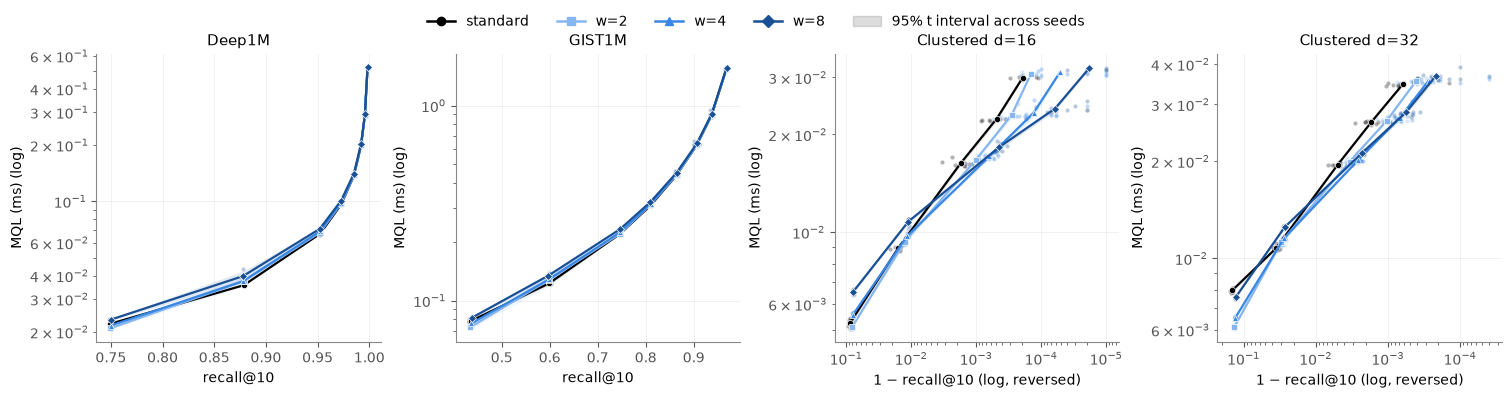

10 clustered per-seed points with recall = 1 are off the log axis and not drawn.


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), constrained_layout=True)
for ax, ds in zip(axes, rd.DATASETS):
    ax.set_yscale("log")
    x = rp.recall_axis(ax, ds)
    rp.curves(ax, runs[runs.dataset == ds], x, "latency_ms")
    ax.set_title(ds)
fig.get_layout_engine().set(rect=(0, 0, 1, 0.93))
rp.width_legend(fig)
plt.show()
print(f"{int((runs.one_minus_recall <= 0).sum())} clustered per-seed points with recall = 1 are off the log axis and not drawn.")

In [5]:
display(rd.fig1_table(runs).round(4))

recall_at_10                         latency_ms                         latency_ms ±                        
width                         1       2       4       8          1       2       4       8            1       2       4       8
dataset        ef0                                                                                                             
Deep1M         10        0.7495  0.7495  0.7500  0.7500     0.0221  0.0209  0.0216  0.0233       0.0001  0.0002  0.0002  0.0002
               23        0.8786  0.8784  0.8781  0.8777     0.0355  0.0373  0.0374  0.0397       0.0001  0.0022  0.0004  0.0025
               52        0.9524  0.9522  0.9522  0.9520     0.0670  0.0679  0.0689  0.0712       0.0005  0.0004  0.0003  0.0005
               79        0.9729  0.9728  0.9727  0.9727     0.0964  0.0973  0.0982  0.1007       0.0007  0.0005  0.0009  0.0009
               120       0.9852  0.9851  0.9851  0.9851     0.1376  0.1375  0.1386  0.1408       0.0013  0.0011  0.0007  0.0008
               182       0.9921  0.9921  0.9921  0.9921     0.2005  0.1995  0.2010  0.2027       0.0062  0.0016  0.0024  0.0010
               275       0.9957  0.9957  0.9957  0.9957     0.2892  0.2888  0.2899  0.2923       0.0080  0.0009  0.0018  0.0020
               512       0.9983  0.9983  0.9983  0.9983     0.5197  0.5200  0.5213  0.5229       0.0046  0.0047  0.0030  0.0024
GIST1M         10        0.4352  0.4348  0.4369  0.4376     0.0785  0.0731  0.0764  0.0816       0.0010  0.0015  0.0017  0.0015
               23        0.5986  0.5979  0.5981  0.5975     0.1225  0.1274  0.1284  0.1344       0.0020  0.0088  0.0055  0.0030
               52        0.7458  0.7463  0.7465  0.7461     0.2193  0.2203  0.2241  0.2318       0.0022  0.0016  0.0009  0.0007
               79        0.8099  0.8099  0.8102  0.8097     0.3073  0.3105  0.3124  0.3201       0.0040  0.0015  0.0035  0.0018
               120       0.8639  0.8642  0.8641  0.8643     0.4390  0.4415  0.4463  0.4524       0.0064  0.0060  0.0079  0.0097
               182       0.9061  0.9064  0.9066  0.9067     0.6262  0.6264  0.6342  0.6396       0.0046  0.0138  0.0101  0.0137
               275       0.9371  0.9374  0.9375  0.9377     0.8912  0.8954  0.8999  0.9085       0.0145  0.0087  0.0156  0.0260
               512       0.9680  0.9681  0.9682  0.9683     1.5414  1.5334  1.5441  1.5589       0.0298  0.0255  0.0260  0.0229
Clustered d=16 10        0.9131  0.9193  0.9212  0.9217     0.0052  0.0051  0.0056  0.0065       0.0001  0.0000  0.0000  0.0001
               23        0.9842  0.9875  0.9886  0.9890     0.0089  0.0093  0.0097  0.0108       0.0001  0.0001  0.0001  0.0001
               52        0.9983  0.9990  0.9994  0.9996     0.0163  0.0167  0.0171  0.0183       0.0003  0.0002  0.0003  0.0003
               79        0.9995  0.9997  0.9999  0.9999     0.0224  0.0230  0.0233  0.0241       0.0004  0.0005  0.0007  0.0004
               120       0.9998  0.9999  1.0000  1.0000     0.0299  0.0308  0.0311  0.0320       0.0002  0.0005  0.0005  0.0004
Clustered d=32 10        0.8555  0.8656  0.8698  0.8709     0.0079  0.0061  0.0065  0.0076       0.0001  0.0000  0.0000  0.0000
               23        0.9644  0.9699  0.9723  0.9730     0.0107  0.0112  0.0115  0.0125       0.0001  0.0003  0.0001  0.0001
               52        0.9950  0.9966  0.9974  0.9977     0.0195  0.0199  0.0202  0.0213       0.0001  0.0001  0.0002  0.0002
               79        0.9983  0.9990  0.9993  0.9994     0.0264  0.0267  0.0272  0.0283       0.0002  0.0002  0.0003  0.0006
               120       0.9994  0.9996  0.9997  0.9998     0.0348  0.0355  0.0356  0.0367       0.0003  0.0003  0.0004  0.0007

## Figure 2. Total distance computations and MQL vs recall
**Question:** at equal recall, which schedule does less work and answers faster?
**Reading:** on the clustered sets the w curves lie below standard at equal recall; on Deep1M and GIST1M they lie on or just above it.
Clustered sets use ef0 ≤ 52 and a 1 − recall log axis. The table gives the seed-mean work and the time per distance computation,
which is why the MQL and work deltas differ.

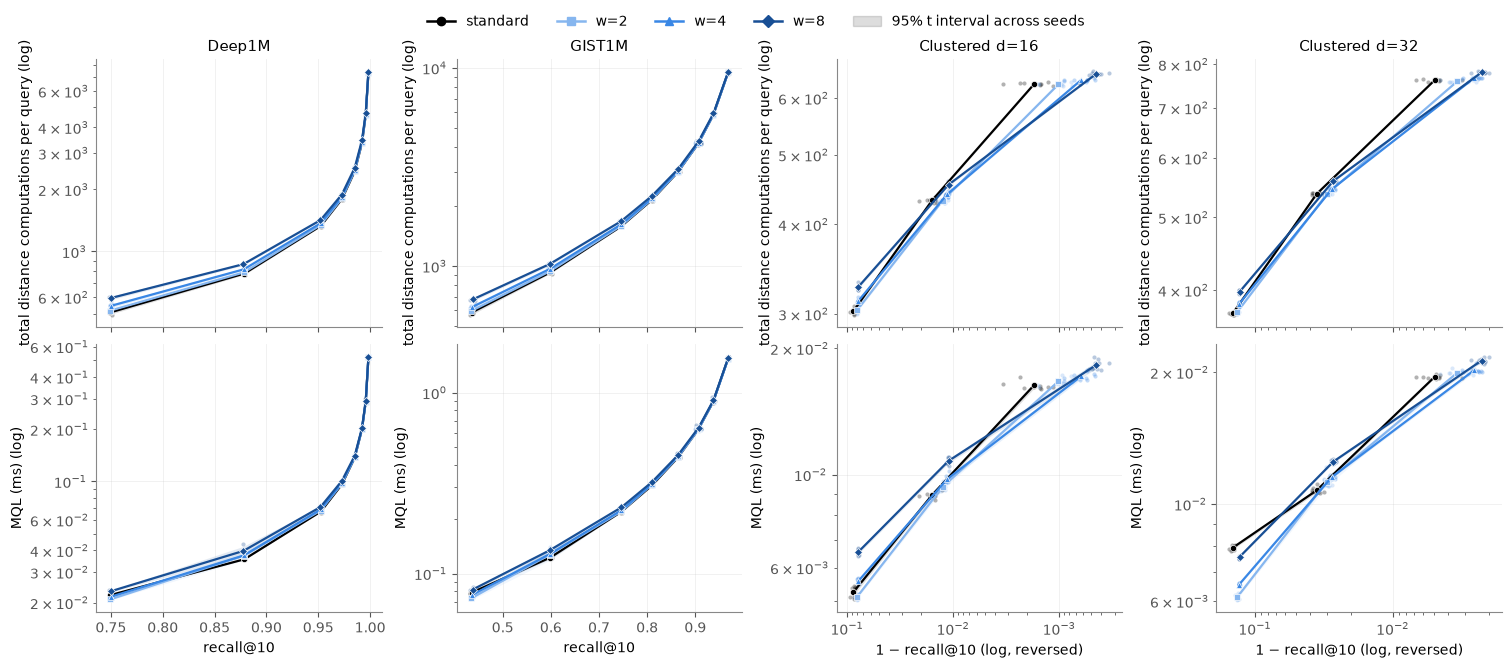

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.6), constrained_layout=True, sharex="col")
for j, ds in enumerate(rd.DATASETS):
    efmax = rd.MATCH_EF_MAX if ds in rd.CLUSTERED else max(EFS[ds])
    d = runs[(runs.dataset == ds) & (runs.ef0 <= efmax)]
    x = rp.recall_axis(axes[1, j], ds)
    for ax, y in ((axes[0, j], "dist_total"), (axes[1, j], "latency_ms")):
        ax.set_yscale("log")
        rp.curves(ax, d, x, y)
    axes[0, j].set(title=ds, xlabel="")  # x is shared down the column
fig.get_layout_engine().set(rect=(0, 0, 1, 0.95))
rp.width_legend(fig)
plt.show()

In [7]:
display(rd.fig2_table(runs).round({**{("dist_total", w): 1 for w in rd.WIDTHS}, **{("ns_per_dist", w): 2 for w in rd.WIDTHS}}))

dist_total                         ns_per_dist                        
width                       1       2       4       8           1       2       4       8
dataset        ef0                                                                       
Deep1M         10       506.4   517.0   544.7   594.5       43.63   40.40   39.70   39.12
               23       781.4   791.8   819.0   867.8       45.49   47.13   45.67   45.77
               52      1330.8  1342.1  1369.7  1418.4       50.38   50.63   50.32   50.19
GIST1M         10       582.5   593.3   621.7   678.1      134.71  123.14  122.82  120.35
               23       928.6   940.7   968.0  1023.2      131.94  135.46  132.63  131.33
               52      1585.9  1597.8  1627.3  1685.1      138.31  137.88  137.70  137.59
Clustered d=16 10       302.7   303.3   312.3   327.1       17.34   16.83   17.81   19.99
               23       432.0   431.7   440.2   454.3       20.69   21.64   22.13   23.73
               52       628.0   627.0   635.3   648.8       26.03   26.60   26.97   28.15
Clustered d=32 10       372.6   373.9   383.3   397.9       21.33   16.39   17.08   19.03
               23       537.4   536.7   545.1   558.9       19.99   20.92   21.13   22.35
               52       761.7   759.1   766.9   780.2       25.62   26.27   26.36   27.25

## Figure 3. Delta vs standard at matched recall
**Question:** at the recall a w run reaches, how much more or less work and latency does it need than standard on the same seed?
**Reading:** the clustered sets need 2–5% less total work at matched recall (interval below 0 for every w) and 5–12% less MQL,
except w=8 on d=16 (MQL +2.6%, interval spans 0); Deep1M and GIST1M need more, growing with w (w=8: about +6% work, +4–5% MQL).
Solid is MQL, dashed is total distance computations, in %; standard is interpolated in log(1 − recall); bands are 95% t intervals.
The table averages each seed over its matched ef0 points, then across seeds.

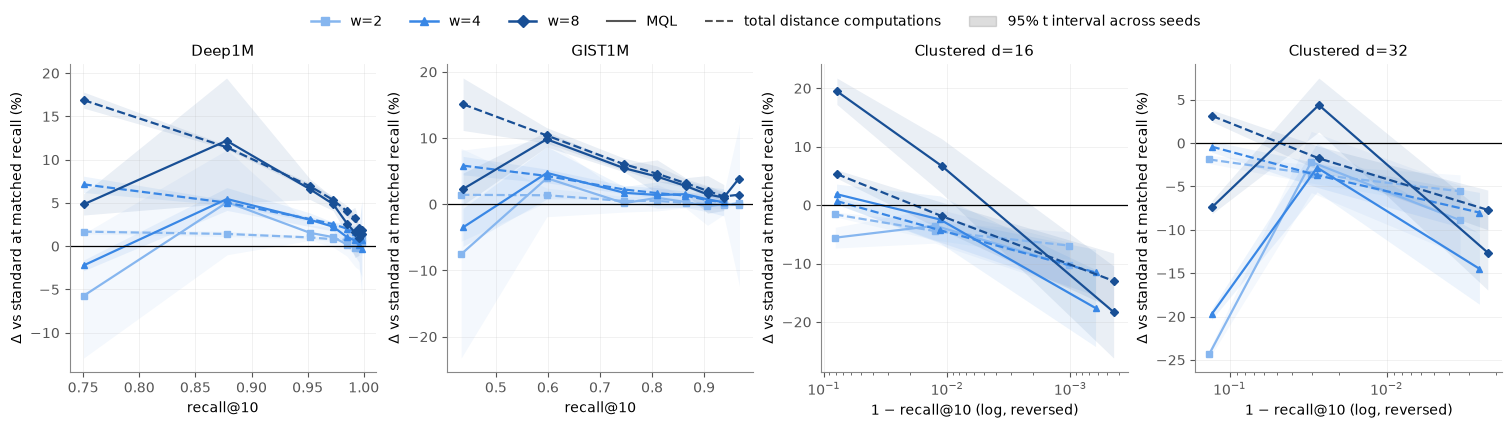

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), constrained_layout=True)
for ax, ds in zip(axes, rd.DATASETS):
    x = rp.recall_axis(ax, ds)
    rp.delta_vs_standard(ax, matched[matched.dataset == ds], x, ["latency_delta_pct", "dist_total_delta_pct"])
    ax.set_title(ds)
fig.get_layout_engine().set(rect=(0, 0, 1, 0.91))
rp.width_legend(fig, rd.WS, extra=[("MQL", "-"), ("total distance computations", "--")])
plt.show()

In [9]:
display(pd.concat({c: rd.matched_summary(matched, c) for c in ["dist_total_delta_pct", "latency_delta_pct"]}, axis=1).round(3))

dist_total_delta_pct                                                          latency_delta_pct                                                           
                                     mean  ci_lo  ci_hi seed_min seed_max n_seeds n_below_0 sign_p              mean   ci_lo   ci_hi seed_min seed_max n_seeds n_below_0 sign_p
dataset        width                                                                                                                                                           
Deep1M         2                    0.837  0.735  0.939    0.729    0.924       5         0  0.062             0.842   0.192   1.492   -0.008    1.312       5         1  0.375
               4                    2.845  2.259  3.432    2.092    3.342       5         0  0.062             1.627   0.910   2.344    1.162    2.578       5         0  0.062
               8                    6.387  5.068  7.707    4.899    7.300       5         0  0.062             4.709   3.892   5.527    3.872    5.685       5         0  0.062
GIST1M         2                    0.422 -0.116  0.960   -0.163    0.841       5         1  0.375             0.330  -1.011   1.670   -0.609    1.845       5         3  1.000
               4                    2.203  1.682  2.725    1.742    2.683       5         0  0.062             1.157   0.092   2.223    0.158    2.340       5         0  0.062
               8                    5.370  3.704  7.036    3.968    7.042       5         0  0.062             3.941   3.133   4.750    3.059    4.657       5         0  0.062
Clustered d=16 2                   -4.327 -5.609 -3.046   -7.085   -0.958      10        10  0.002            -6.469  -8.613  -4.324  -11.150   -1.175      10        10  0.002
               4                   -5.037 -6.973 -3.101   -8.765    0.694      10         9  0.021            -6.068  -9.195  -2.941  -11.588    3.566      10         9  0.021
               8                   -3.184 -5.598 -0.770   -8.700    3.174      10         8  0.109             2.626  -1.596   6.849   -7.711   11.854      10         3  0.344
Clustered d=32 2                   -3.660 -4.690 -2.631   -6.898   -1.710      10        10  0.002           -11.790 -13.938  -9.642  -17.922   -7.280      10        10  0.002
               4                   -4.035 -5.390 -2.680   -7.570   -1.060      10        10  0.002           -12.354 -14.581 -10.128  -18.336   -7.883      10        10  0.002
               8                   -2.106 -3.454 -0.759   -5.537    1.466      10         9  0.021            -5.204  -7.562  -2.847  -11.172    0.744      10         9  0.021

## Figure 4. Cost by layer at equal ef0
**Question:** at the same ef0, does the level-0 work the better entry saves pay for the extra level-1 work?
**Reading:** no. Level-1 extra is flat in ef0 and larger than the level-0 saving everywhere except w=2 on the clustered sets at
ef0 ≥ 23, where the net is slightly positive. Absolute values first, then in % of standard total; bands are 95% t intervals.

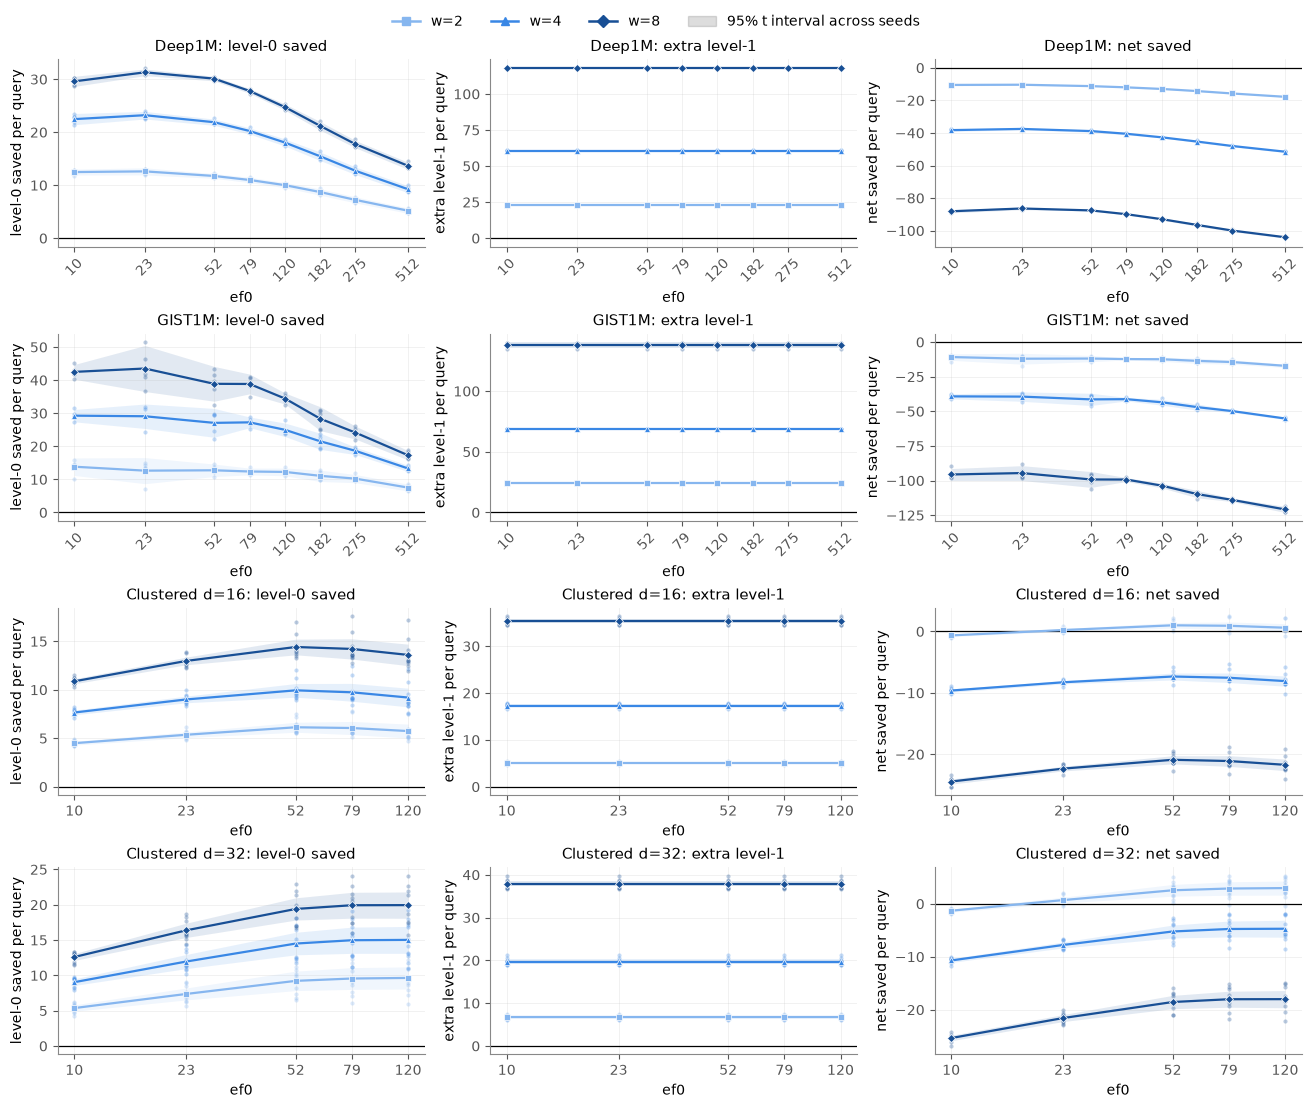

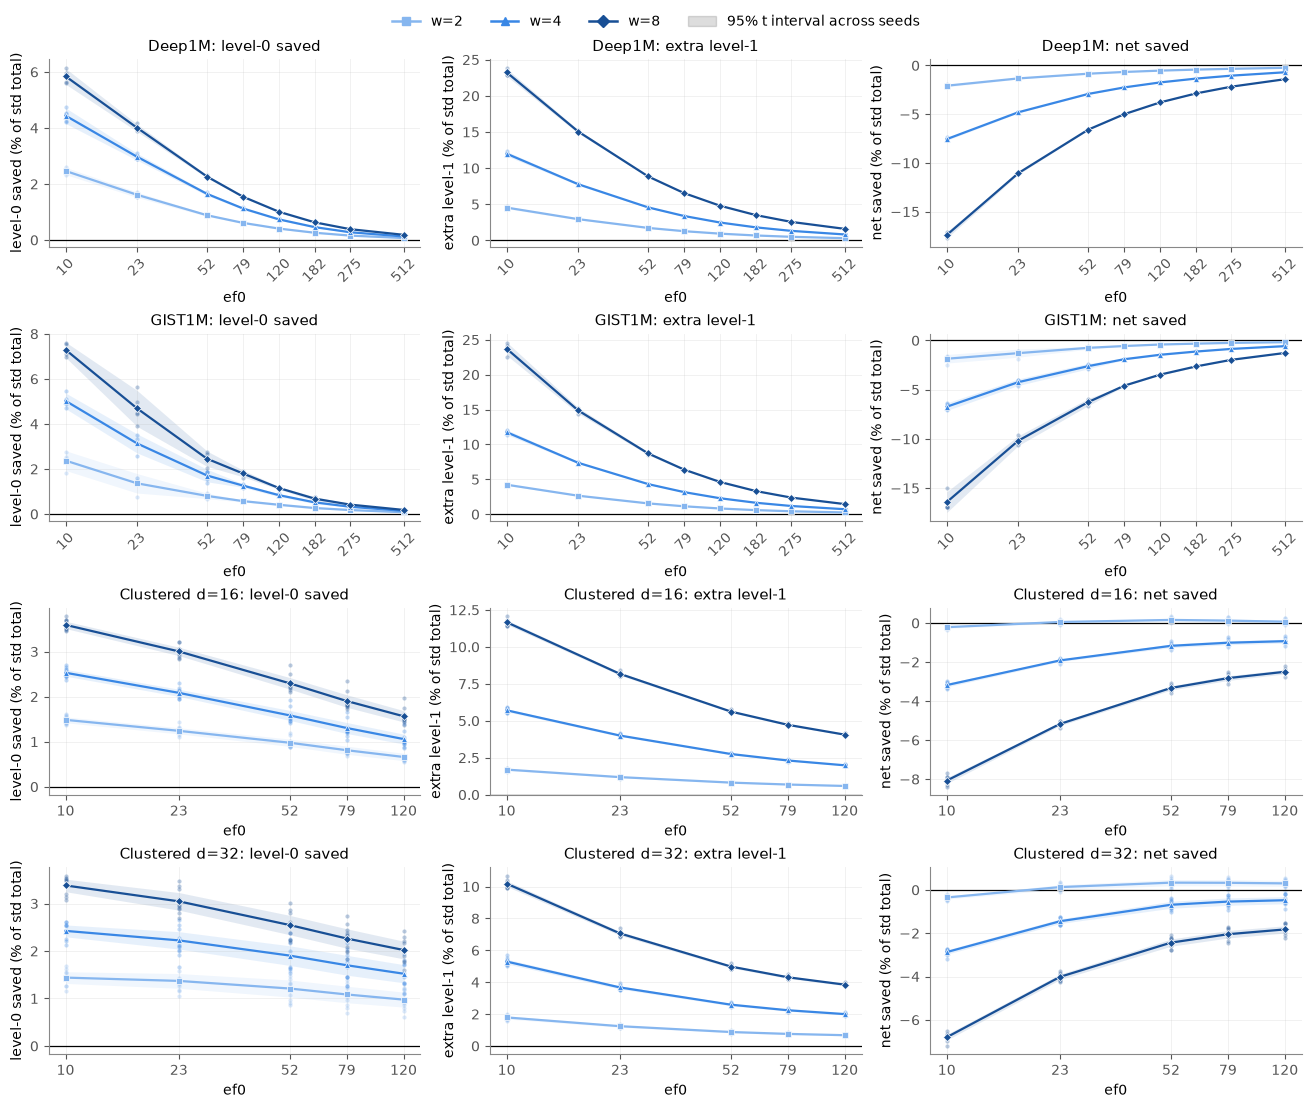

In [10]:
PANELS = [("layer0_saved", "level-0 saved"), ("layer1_extra", "extra level-1"), ("net_saved", "net saved")]
for suffix in ("", "_pct"):
    fig, axes = plt.subplots(4, 3, figsize=(13, 11), constrained_layout=True, sharex="row")
    for i, ds in enumerate(rd.DATASETS):
        for j, (col, title) in enumerate(PANELS):
            ax = axes[i, j]
            rp.ef_axis(ax, EFS[ds])
            rp.curves(ax, paired[paired.dataset == ds], "ef0", col + suffix)
            ax.axhline(0, color="#000000", lw=0.9)
            ax.set_title(f"{ds}: {title}")
    fig.get_layout_engine().set(rect=(0, 0, 1, 0.97))
    rp.width_legend(fig, rd.WS)
    plt.show()

In [11]:
fig4 = rd.fig4_table(paired)
r4 = {c: (5 if c == "recall_gain" else 3 if "pct" in c or c == "net_sign_p" else 2) for c in fig4.columns}
print("Net balance at equal ef0, clustered sets, ef0 10–52:")
display(fig4.loc[(rd.CLUSTERED, [10, 23, 52], slice(None))].round(r4))
print("Net balance, Deep1M and GIST1M:")
display(fig4.loc[(rd.DATASETS[:2], slice(None), slice(None))].round(r4))

Net balance at equal ef0, clustered sets, ef0 10–52:


layer0_saved  layer1_extra  net_saved  net_ci_lo  net_ci_hi  net_min  net_max  net_pct  net_pct_ci_lo  net_pct_ci_hi  net_pct_min  net_pct_max  seeds_net_pos  seeds  net_sign_p  recall_gain
dataset        ef0 width                                                                                                                                                                                               
Clustered d=16 10  2              4.49          5.14      -0.64      -0.82      -0.47    -1.14    -0.34   -0.213         -0.271         -0.155       -0.374       -0.111              0     10       0.002      0.00616
                   4              7.66         17.28      -9.62      -9.90      -9.35   -10.23    -8.94   -3.180         -3.276         -3.084       -3.374       -2.948              0     10       0.002      0.00809
                   8             10.87         35.31     -24.44     -24.85     -24.02   -25.28   -23.36   -8.074         -8.224         -7.925       -8.390       -7.704              0     10       0.002      0.00858
               23  2              5.36          5.14       0.23      -0.01       0.46    -0.33     0.85    0.052         -0.002          0.106       -0.077        0.197              8     10       0.109      0.00323
                   4              9.00         17.28      -8.28      -8.54      -8.02    -9.07    -7.80   -1.916         -1.975         -1.858       -2.098       -1.803              0     10       0.002      0.00435
                   8             12.98         35.31     -22.33     -22.71     -21.96   -23.37   -21.65   -5.170         -5.254         -5.087       -5.404       -5.007              0     10       0.002      0.00473
               52  2              6.13          5.14       1.00       0.56       1.44     0.03     2.16    0.159          0.088          0.229        0.005        0.343             10     10       0.002      0.00070
                   4              9.94         17.28      -7.34      -7.91      -6.77    -8.79    -5.81   -1.168         -1.259         -1.078       -1.402       -0.924              0     10       0.002      0.00109
                   8             14.41         35.31     -20.89     -21.56     -20.23   -22.66   -19.39   -3.328         -3.434         -3.221       -3.611       -3.084              0     10       0.002      0.00127
Clustered d=32 10  2              5.37          6.67      -1.31      -1.57      -1.05    -1.84    -0.75   -0.351         -0.420         -0.281       -0.491       -0.200              0     10       0.002      0.01007
                   4              9.03         19.73     -10.70     -11.07     -10.33   -11.83   -10.07   -2.872         -2.971         -2.773       -3.176       -2.713              0     10       0.002      0.01429
                   8             12.60         37.95     -25.35     -25.86     -24.84   -26.85   -24.24   -6.804         -6.936         -6.673       -7.208       -6.528              0     10       0.002      0.01540
               23  2              7.37          6.67       0.69       0.14       1.24    -0.43     1.95    0.129          0.027          0.231       -0.080        0.362              9     10       0.021      0.00544
                   4             11.95         19.73      -7.78      -8.34      -7.21    -8.71    -6.62   -1.448         -1.554         -1.342       -1.619       -1.231              0     10       0.002      0.00790
                   8             16.37         37.95     -21.58     -22.24     -20.92   -22.93   -20.06   -4.015         -4.140         -3.890       -4.262       -3.728              0     10       0.002      0.00860
               52  2              9.22          6.67       2.55       1.45       3.65     0.18     5.05    0.334          0.190          0.478        0.024        0.661             10     10       0.002      0.00156
                   4             14.50         19.73      -5.23      -6.45      -4.01    -7.72    -2.77   -0.687         -0.848         -0

Net balance, Deep1M and GIST1M:


layer0_saved  layer1_extra  net_saved  net_ci_lo  net_ci_hi  net_min  net_max  net_pct  net_pct_ci_lo  net_pct_ci_hi  net_pct_min  net_pct_max  seeds_net_pos  seeds  net_sign_p  recall_gain
dataset ef0 width                                                                                                                                                                                               
Deep1M  10  2             12.48         23.00     -10.52     -11.04     -10.00   -10.96    -9.84   -2.078         -2.206         -1.950       -2.169       -1.923              0      5       0.062      0.00004
            4             22.47         60.75     -38.28     -39.00     -37.55   -38.94   -37.58   -7.559         -7.689         -7.428       -7.625       -7.377              0      5       0.062      0.00054
            8             29.59        117.69     -88.10     -89.04     -87.15   -89.02   -87.34  -17.398        -17.723        -17.074      -17.727      -17.067              0      5       0.062      0.00052
        23  2             12.61         23.00     -10.39     -10.82      -9.96   -10.84    -9.92   -1.330         -1.393         -1.266       -1.385       -1.255              0      5       0.062     -0.00026
            4             23.21         60.75     -37.54     -38.12     -36.95   -38.04   -37.03   -4.804         -4.873         -4.734       -4.879       -4.725              0      5       0.062     -0.00053
            8             31.30        117.69     -86.39     -87.12     -85.65   -87.02   -85.57  -11.056        -11.180        -10.931      -11.168      -10.931              0      5       0.062     -0.00087
        52  2             11.75         23.00     -11.26     -11.50     -11.01   -11.50   -11.02   -0.846         -0.868         -0.824       -0.865       -0.827              0      5       0.062     -0.00018
            4             21.89         60.75     -38.86     -39.60     -38.12   -39.70   -38.28   -2.920         -2.972         -2.869       -2.986       -2.874              0      5       0.062     -0.00023
            8             30.11        117.69     -87.58     -87.93     -87.23   -87.88   -87.23   -6.581         -6.623         -6.539       -6.624       -6.552              0      5       0.062     -0.00036
        79  2             10.99         23.00     -12.01     -12.17     -11.85   -12.21   -11.90   -0.668         -0.678         -0.658       -0.680       -0.661              0      5       0.062     -0.00009
            4             20.23         60.75     -40.51     -41.20     -39.83   -41.09   -39.95   -2.252         -2.286         -2.219       -2.288       -2.219              0      5       0.062     -0.00017
            8             27.78        117.69     -89.91     -90.39     -89.42   -90.35   -89.48   -4.999         -5.027         -4.971       -5.027       -4.968              0      5       0.062     -0.00020
        120 2             10.01         23.00     -12.99     -13.24     -12.74   -13.28   -12.76   -0.530         -0.541         -0.518       -0.541       -0.519              0      5       0.062     -0.00006
            4             18.04         60.75     -42.70     -43.08     -42.33   -42.97   -42.23   -1.741         -1.752         -1.730       -1.754       -1.731              0      5       0.062     -0.00010
            8             24.73        117.69     -92.96     -93.53     -92.39   -93.47   -92.32   -3.790         -3.809         -3.771       -3.808       -3.769              0      5       0.062     -0.00009
        182 2              8.70         23.00     -14.30     -14.54     -14.05   -14.64   -14.14   -0.426         -0.433         -0.419       -0.436       -0.421              0      5       0.062     -0.00004
            4             15.44         60.75     -45.31     -45.89     -44.73   -45.66   -44.54   -1.349         -1.363         -1.335       -1.359       -1.331              0      5       0.062     -0.00006
            8             21.18        117.69   

## Figure 5. Distance from the query to `ep1`
**Question:** does the wider level-1 beam hand level 0 a closer entry point?
**Reading:** yes, by a few % at the median, and only for the 19% to 69% of queries whose `ep1` changes; it never gets farther.
Seeds pooled; one panel per dataset because `ep1` does not depend on ef0 (checked). Violins are cut at p0.5–p99.5;
the share of queries with `ep1` unchanged is printed above each.

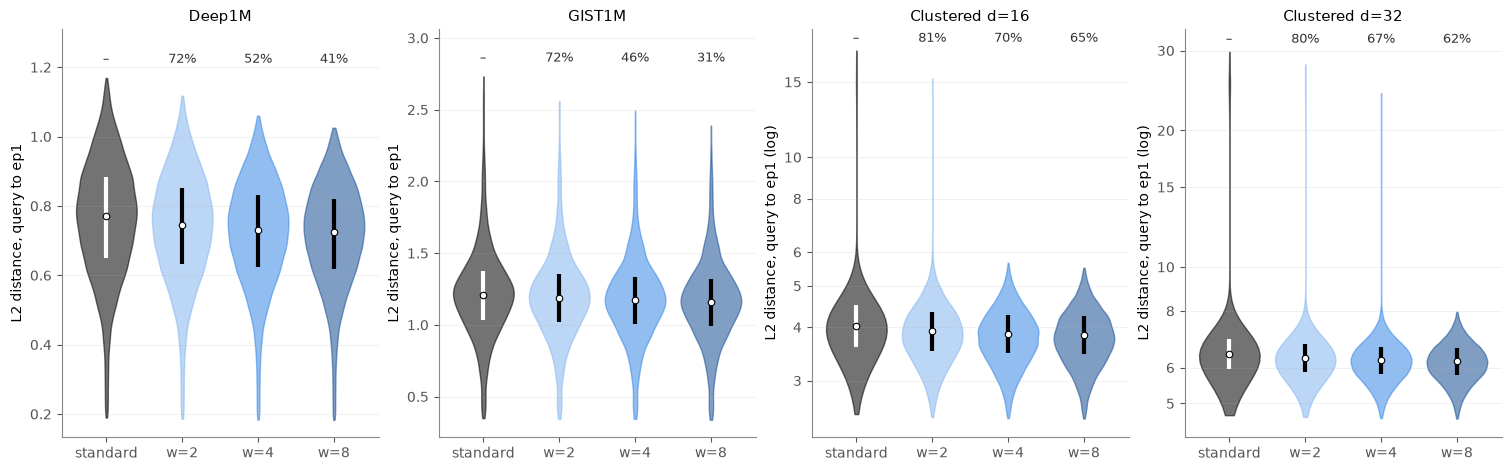

In [12]:
entries = rd.entry_distances(queries)
fig, axes = plt.subplots(1, 4, figsize=(15, 4.6), constrained_layout=True)
for ax, ds in zip(axes, rd.DATASETS):
    rp.entry_violins(ax, entries[entries.dataset == ds], log=ds in rd.CLUSTERED)
    ax.set_title(ds)
plt.show()

In [13]:
display(rd.entry_table(entries).round(3))

median     q1     q3  unchanged_id  closer  farther  unchanged_ci_lo  unchanged_ci_hi
dataset        width                                                                                       
Deep1M         1       0.771  0.650  0.884         1.000   0.000      0.0            1.000            1.000
               2       0.746  0.633  0.853         0.719   0.281      0.0            0.716            0.722
               4       0.731  0.624  0.831         0.515   0.485      0.0            0.509            0.522
               8       0.724  0.619  0.819         0.412   0.588      0.0            0.407            0.416
GIST1M         1       1.209  1.034  1.376         1.000   0.000      0.0            1.000            1.000
               2       1.188  1.020  1.354         0.720   0.279      0.0            0.709            0.732
               4       1.171  1.006  1.336         0.463   0.536      0.0            0.456            0.471
               8       1.161  0.995  1.321         0.308   0.692      0.0            0.281            0.335
Clustered d=16 1       4.027  3.590  4.507         1.000   0.000      0.0            1.000            1.000
               2       3.920  3.517  4.350         0.813   0.187      0.0            0.810            0.816
               4       3.866  3.476  4.277         0.697   0.303      0.0            0.694            0.700
               8       3.842  3.459  4.245         0.649   0.351      0.0            0.646            0.652
Clustered d=32 1       6.415  5.945  6.936         1.000   0.000      0.0            1.000            1.000
               2       6.288  5.856  6.746         0.798   0.202      0.0            0.793            0.802
               4       6.221  5.806  6.654         0.674   0.326      0.0            0.668            0.680
               8       6.193  5.784  6.616         0.619   0.381      0.0            0.612            0.625

## Figure 6. Level-0 sensitivity to the entry point
**Question:** how much level-0 work does a closer `ep1` save, per query?
**Reading:** about 9–12% per 10% closer at ef0 = 10 on Deep1M and GIST1M, falling to under 1% at high ef0; about 1.3–2% on the clustered sets.
Queries pooled across seeds and widths, one panel per ef0, x on a log-ratio axis with % labels.
The elasticity is fitted per seed (all queries, as in the original notebook) and reported as the seed mean with a 95% t interval;
the appendix repeats it without the unchanged-`ep1` queries.

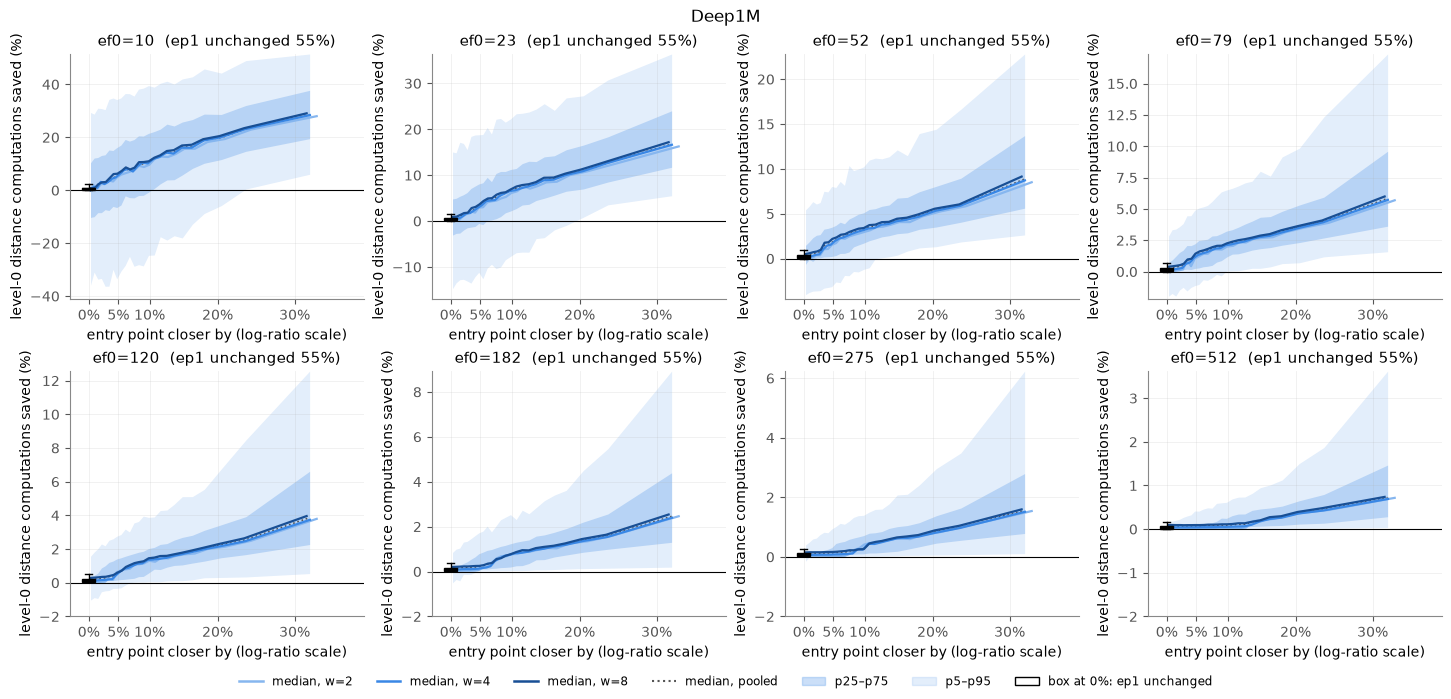

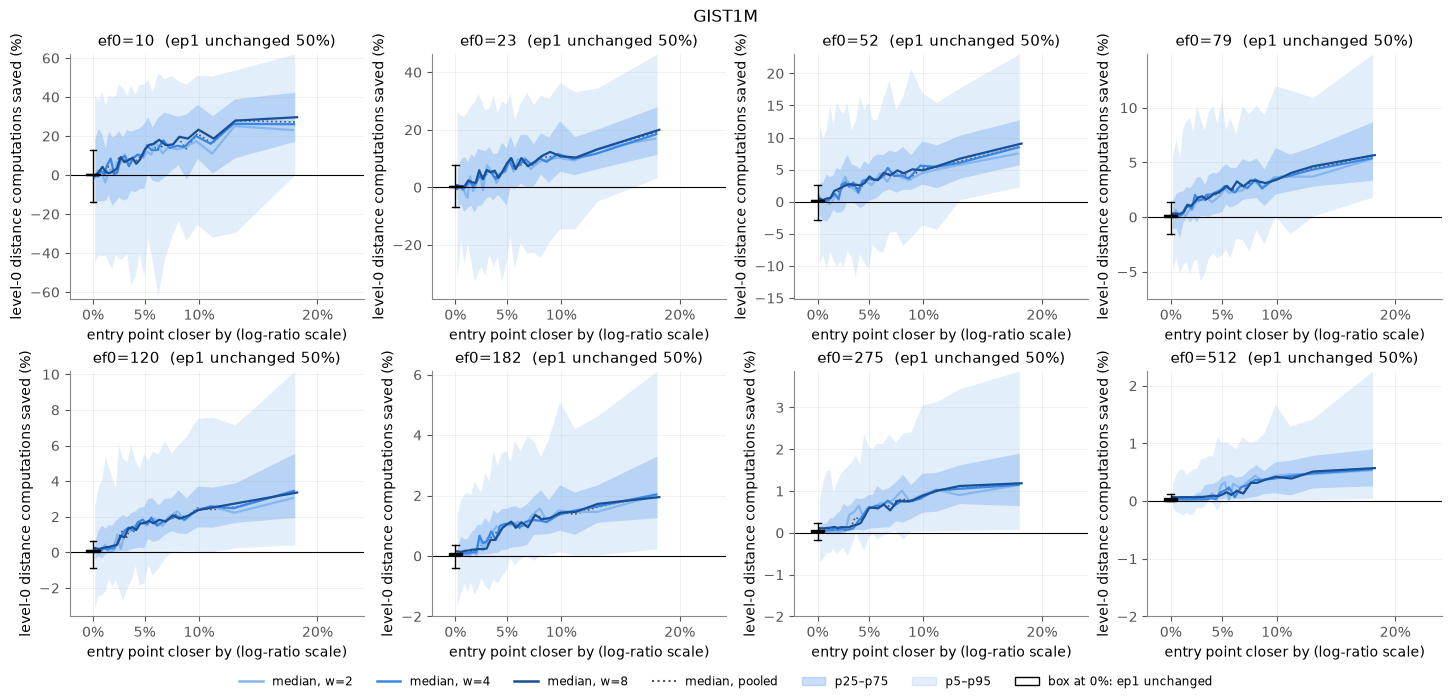

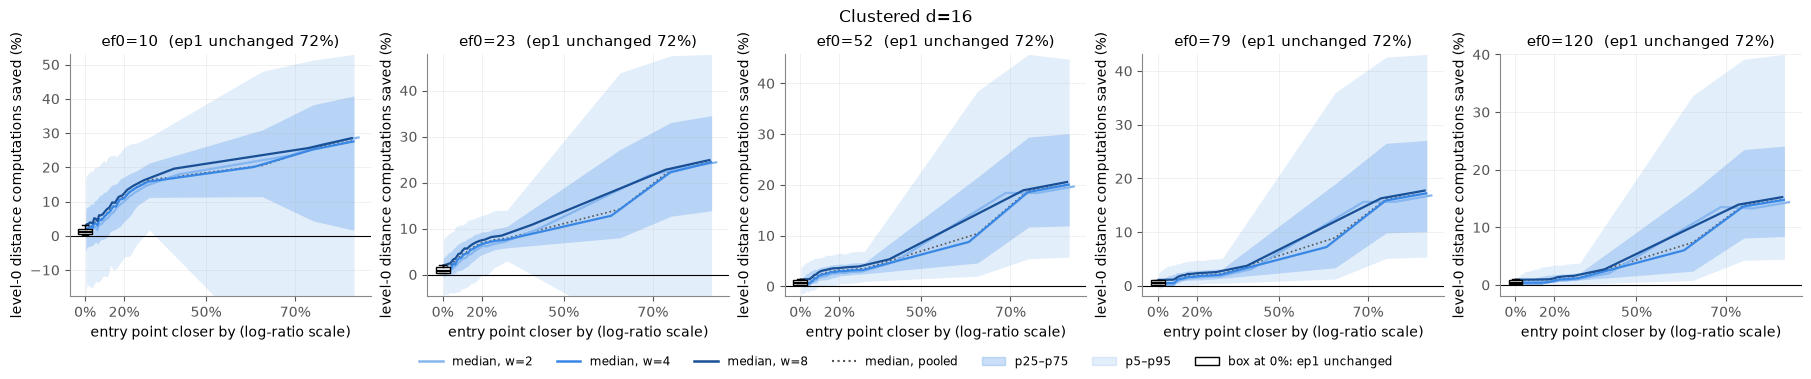

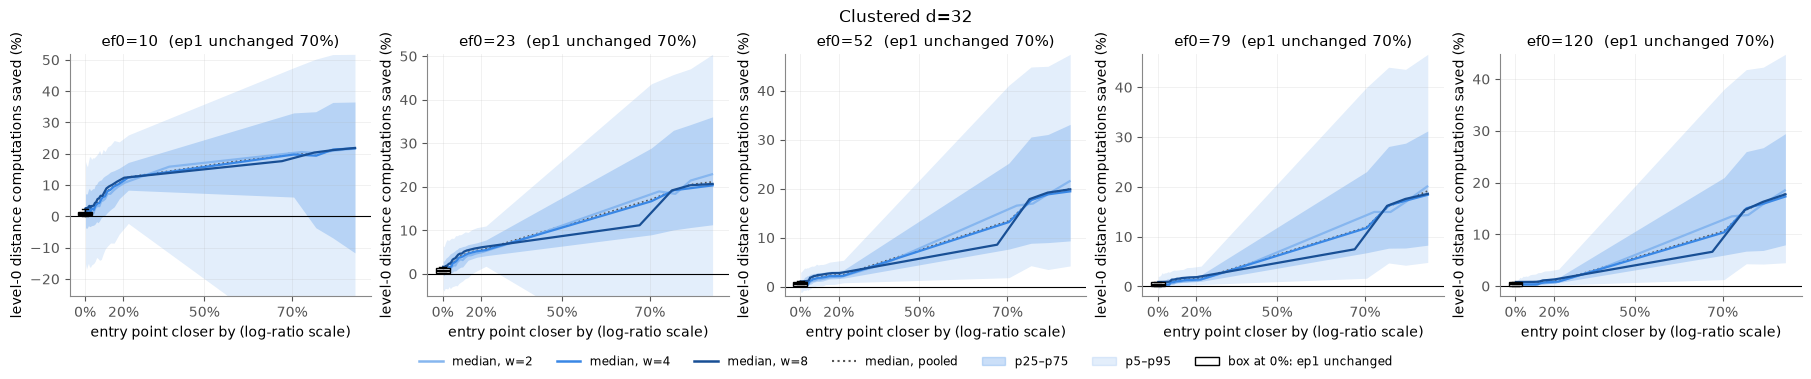

In [14]:
for ds in rd.DATASETS:
    ncols = 5 if ds in rd.CLUSTERED else 4
    nrows = -(-len(EFS[ds]) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.2 * nrows + 0.5), constrained_layout=True, squeeze=False)
    for ax, ef in zip(axes.flat, EFS[ds]):
        rp.sensitivity_fan(ax, rd.fig6_pairs(queries, ds, ef))
    for ax in axes.flat[len(EFS[ds]):]:
        ax.axis("off")
    fig.suptitle(ds)
    rp.sensitivity_legend(fig)
    plt.show()

In [15]:
print("Elasticity, widths pooled, as % level-0 saving per 10% closer entry point (seed mean, 95% t interval, seed range):")
display(rd.elasticity(queries).round(3))
print("Level-0 saving (%), queries with unchanged ep1 vs closer ep1, and the share of the mean saving from unchanged-ep1 queries:")
display(rd.zero_table(queries).round(3))

Elasticity, widths pooled, as % level-0 saving per 10% closer entry point (seed mean, 95% t interval, seed range):


elasticity  pct_per_10pct  ci_lo   ci_hi  seed_min  seed_max  share_near  near_pct_per_10pct  near_min  near_max  queries_per_seed
dataset        ef0                                                                                                                                    
Deep1M         10        0.904          9.080  8.703   9.457     8.653     9.346       0.989              10.444    10.198    10.517           29995.8
               23        0.523          5.357  5.125   5.589     5.167     5.619       0.989               6.048     5.999     6.146           29995.8
               52        0.263          2.736  2.623   2.849     2.587     2.812       0.989               3.007     2.963     3.030           29995.8
               79        0.176          1.834  1.724   1.944     1.692     1.896       0.989               1.981     1.957     1.998           29995.8
               120       0.114          1.189  1.099   1.279     1.089     1.266       0.989               1.261     1.241     1.289           29995.8
               182       0.071          0.750  0.686   0.814     0.690     0.814       0.989               0.773     0.754     0.794           29995.8
               275       0.044          0.458  0.412   0.505     0.412     0.498       0.989               0.461     0.447     0.479           29995.8
               512       0.020          0.210  0.181   0.240     0.181     0.241       0.989               0.197     0.186     0.213           29995.8
GIST1M         10        1.240         12.165  6.902  17.427     5.745    17.406       0.998              18.425    17.065    19.572            3000.0
               23        0.709          7.168  4.020  10.317     3.314    10.192       0.998              11.205     9.663    12.299            3000.0
               52        0.326          3.370  1.849   4.890     1.595     4.840       0.998               5.712     5.382     6.230            3000.0
               79        0.217          2.260  1.240   3.280     1.033     3.197       0.998               3.934     3.656     4.571            3000.0
               120       0.133          1.394  0.765   2.023     0.669     1.999       0.998               2.506     2.322     2.944            3000.0
               182       0.079          0.833  0.451   1.214     0.401     1.208       0.998               1.533     1.345     1.829            3000.0
               275       0.047          0.496  0.268   0.725     0.227     0.686       0.998               0.929     0.840     1.096            3000.0
               512       0.021          0.223  0.120   0.326     0.107     0.314       0.998               0.419     0.380     0.496            3000.0
Clustered d=16 10        0.197          2.052  1.874   2.229     1.571     2.290       0.959               4.725     4.603     4.939           30000.0
               23        0.186          1.943  1.798   2.088     1.621     2.281       0.959               2.697     2.610     2.792           30000.0
               52        0.168          1.754  1.661   1.848     1.529     1.919       0.959               1.250     1.210     1.289           30000.0
               79        0.148          1.546  1.437   1.654     1.270     1.816       0.959               0.749     0.705     0.782           30000.0
               120       0.128          1.339  1.237   1.442     1.050     1.595       0.959               0.401     0.374     0.436           30000.0
Clustered d=32 10        0.134          1.405  1.267   1.544     1.184     1.736       0.952               5.169     4.846     5.515           30000.0
               23        0.159          1.661  1.524   1.797     1.334     1.896       0.952               2.683     2.442     2.839           30000.0
               52        0.163          1.703  1.562   1.844     1.468     2.055       0.952               1.205     1.107     1.288           30000.0
               79        0.155          1.620  1.471   1.768     1.300     1.934       0.952  

Level-0 saving (%), queries with unchanged ep1 vs closer ep1, and the share of the mean saving from unchanged-ep1 queries:


share_x0  y_mean_x0  y_median_x0  y_mean_xpos  y_median_xpos  y_mean_all  y_median_all  saving_share_unchanged
dataset        ef0                                                                                                                
Deep1M         10      0.549      0.546        0.356        9.219         10.750       4.462         0.627                   0.067
               23      0.549      0.442        0.251        6.350          6.026       3.110         0.535                   0.078
               52      0.549      0.288        0.168        3.500          2.946       1.738         0.382                   0.091
               79      0.549      0.214        0.134        2.367          1.904       1.186         0.295                   0.099
               120     0.549      0.161        0.102        1.510          1.147       0.770         0.212                   0.115
               182     0.549      0.119        0.075        0.920          0.584       0.480         0.145                   0.135
               275     0.549      0.087        0.055        0.541          0.215       0.292         0.098                   0.163
               512     0.549      0.055        0.034        0.238          0.088       0.137         0.054                   0.218
GIST1M         10      0.497     -0.074        0.218        8.599         11.433       4.285         0.346                  -0.009
               23      0.497      0.280        0.135        5.657          6.504       2.983         0.245                   0.047
               52      0.497      0.069        0.084        3.451          3.234       1.769         0.208                   0.019
               79      0.497      0.122        0.065        2.530          2.230       1.332         0.189                   0.045
               120     0.497      0.077        0.050        1.672          1.441       0.879         0.147                   0.043
               182     0.497      0.065        0.038        1.005          0.837       0.537         0.106                   0.060
               275     0.497      0.049        0.029        0.613          0.425       0.333         0.073                   0.074
               512     0.497      0.031        0.021        0.263          0.086       0.148         0.039                   0.103
Clustered d=16 10      0.720      1.306        1.093        7.612          7.480       3.074         1.342                   0.306
               23      0.720      0.939        0.850        5.937          4.830       2.341         0.932                   0.289
               52      0.720      0.645        0.559        4.260          2.462       1.659         0.593                   0.280
               79      0.720      0.533        0.458        3.390          1.307       1.334         0.478                   0.287
               120     0.720      0.449        0.386        2.669          0.908       1.072         0.397                   0.302
Clustered d=32 10      0.697      0.982        0.791        5.859          6.009       2.461         0.997                   0.278
               23      0.697      0.727        0.658        5.403          3.778       2.145         0.714                   0.236
               52      0.697      0.517        0.452        4.515          1.875       1.730         0.475                   0.208
               79      0.697      0.442        0.384        3.999          1.040       1.521         0.399                   0.203
               120     0.697      0.389        0.339        3.544          0.797       1.346         0.348                   0.202

## Appendix: sensitivity
A. Matched-recall interpolation: log(1 − recall) (default) vs linear in recall, the held-out check behind the choice,
and the points dropped for lying outside the standard range. B. Clustered sets: standard curve also cut at ef0 ≤ 52.
C. MQL delta without the ef0 = 10 points. D. Bands: seed min–max (original) vs 95% t interval.
E. Figure 6 elasticity without the queries whose `ep1` did not change.

In [16]:
linear = rd.matched(runs, "linear")
print("A1. Matched-recall summary, total distance computations and MQL (%), log1m vs linear:")
cols = ["mean", "ci_lo", "ci_hi", "seed_min", "seed_max", "n_below_0", "sign_p"]
display(pd.concat({(c, m.attrs["method"]): rd.matched_summary(m, c)[cols]
                   for c in ["dist_total_delta_pct", "latency_delta_pct"] for m in (matched, linear)}, axis=1).round(3))
print("A2. Seed mean by ef0 (%), total distance computations, log1m vs linear:")
display(pd.concat({m.attrs["method"]: rd.matched_by_ef(m, "dist_total_delta_pct")["mean"].unstack("width")
                   for m in (matched, linear)}, axis=1).round(2))
print("A3. Held-out standard point, interpolation error (% of measured, > 0 = standard overstated):")
display(rd.heldout_interp_error(runs).round(2))
print("A4. Seeds dropped (w recall outside the seed's standard range), log1m and linear:")
display(pd.concat({m.attrs["method"]: rd.dropped_points(m) for m in (matched, linear)}, axis=1).fillna(0).astype(int))

A1. Matched-recall summary, total distance computations and MQL (%), log1m vs linear:


dist_total_delta_pct                                                                                                           latency_delta_pct                                                     \
                                    log1m                                                  linear                                                               log1m                                                      
                                     mean  ci_lo  ci_hi seed_min seed_max n_below_0 sign_p   mean   ci_lo  ci_hi seed_min seed_max n_below_0 sign_p              mean   ci_lo   ci_hi seed_min seed_max n_below_0 sign_p   
dataset        width                                                                                                                                                                                                       
Deep1M         2                    0.837  0.735  0.939    0.729    0.924         0  0.062  0.761   0.646  0.875    0.644    0.856         0  0.062             0.842   0.192   1.492   -0.008    1.312         1  0.375   
               4                    2.845  2.259  3.432    2.092    3.342         0  0.062  2.750   2.191  3.310    2.032    3.200         0  0.062             1.627   0.910   2.344    1.162    2.578         0  0.062   
               8                    6.387  5.068  7.707    4.899    7.300         0  0.062  6.259   4.953  7.566    4.798    7.122         0  0.062             4.709   3.892   5.527    3.872    5.685         0  0.062   
GIST1M         2                    0.422 -0.116  0.960   -0.163    0.841         1  0.375  0.316  -0.286  0.917   -0.371    0.787         1  0.375             0.330  -1.011   1.670   -0.609    1.845         3  1.000   
               4                    2.203  1.682  2.725    1.742    2.683         0  0.062  2.076   1.506  2.647    1.517    2.614         0  0.062             1.157   0.092   2.223    0.158    2.340         0  0.062   
               8                    5.370  3.704  7.036    3.968    7.042         0  0.062  5.210   3.526  6.893    3.752    6.933         0  0.062             3.941   3.133   4.750    3.059    4.657         0  0.062   
Clustered d=16 2                   -4.327 -5.609 -3.046   -7.085   -0.958        10  0.002 -7.147  -8.781 -5.513  -10.675   -2.673        10  0.002            -6.469  -8.613  -4.324  -11.150   -1.175        10  0.002   
               4                   -5.037 -6.973 -3.101   -8.765    0.694         9  0.021 -8.219 -10.265 -6.172  -12.178   -1.948        10  0.002            -6.068  -9.195  -2.941  -11.588    3.566         9  0.021   
               8                   -3.184 -5.598 -0.770   -8.700    3.174         8  0.109 -6.749  -9.217 -4.281  -13.008   -0.753        10  0.002             2.626  -1.596   6.849   -7.711   11.854         3  0.344   
Clustered d=32 2                   -3.660 -4.690 -2.631   -6.898   -1.710        10  0.002 -5.854  -7.156 -4.552   -9.371   -2.847        10  0.002           -11.790 -13.938  -9.642  -17.922   -7.280        10  0.002   
               4                   -4.035 -5.390 -2.680   -7.570   -1.060        10  0.002 -6.828  -8.429 -5.227  -10.586   -2.828        10  0.002           -12.354 -14.581 -10.128  -18.336   -7.883        10  0.002   
               8                   -2.106 -3.454 -0.759   -5.537    1.466         9  0.021 -5.089  -6.671 -3.507   -8.814   -0.522        10  0.002            -5.204  -7.562  -2.847  -11.172    0.744         9  0.021   

                                                                                 
                      linear                                                     
                        mean   ci_lo   ci_hi seed_min seed_max n_below_0 sign_p  
dataset        width                                                             
Deep1M         2       0.752   0.085   1.420   -0.129    1.235         1  0.375  
               4       1.519   0.798   2.241    1.008    2.452         0  0.062  
        

A2. Seed mean by ef0 (%), total distance computations, log1m vs linear:


log1m               linear              
width                  2      4      8      2      4      8
dataset        ef0                                         
Deep1M         10   1.68   7.15  16.89   1.52   6.97  16.68
               23   1.41   5.03  11.44   1.33   4.95  11.32
               52   1.01   3.14   6.93   0.94   3.05   6.79
               79   0.80   2.55   5.34   0.74   2.47   5.22
               120  0.72   2.02   4.04   0.67   1.89   3.91
               182  0.67   1.68   3.23   0.59   1.56   3.12
               275  0.28   1.00   2.09   0.19   0.93   2.01
               512  0.36   0.70   1.89   0.32   0.70   1.70
GIST1M         10   1.43   5.84  15.10   1.31   5.70  14.82
               23   1.36   4.27  10.40   1.17   4.11  10.21
               52   0.50   2.22   6.05   0.42   2.13   5.93
               79   0.51   1.68   4.61   0.44   1.59   4.50
               120  0.19   1.31   3.19   0.12   1.24   3.13
               182  0.01   0.62   2.02  -0.08   0.47   1.89
               275 -0.14   0.29   1.18  -0.28   0.08   0.89
               512  0.18    NaN   1.44   0.18    NaN   1.38
Clustered d=16 10  -1.61   0.70   5.31  -3.35  -1.58   2.81
               23  -4.44  -4.29  -1.89  -9.13 -10.17  -8.26
               52  -6.93 -11.52 -12.98  -8.97 -12.90 -14.80
Clustered d=32 10  -1.89  -0.40   3.13  -3.57  -2.74   0.55
               23  -3.54  -3.70  -1.75  -6.91  -8.25  -6.74
               52  -5.55  -8.01  -7.70  -7.07  -9.50  -9.08

A3. Held-out standard point, interpolation error (% of measured, > 0 = standard overstated):


linear  log1m
dataset        ef0               
Deep1M         23    31.94  10.83
               52    18.56   6.48
               79    12.94   4.04
               120   14.03   4.47
               182   14.89   5.32
               275   23.86   7.73
GIST1M         23    19.55   8.92
               52    12.61   5.99
               79     8.61   3.58
               120    9.87   4.01
               182   10.67   4.23
               275   17.86   6.04
Clustered d=16 23    32.96   2.39
               52    15.04   0.08
Clustered d=32 23    25.85  -0.65
               52    11.27  -0.29

A4. Seeds dropped (w recall outside the seed's standard range), log1m and linear:


log1m       linear      
width           2  4  8      2  4  8
dataset ef0                         
Deep1M  10      3  2  2      3  2  2
        512     3  3  4      3  3  4
GIST1M  10      3  1  2      3  1  2
        512     3  5  4      3  5  4

In [17]:
cut = rd.matched(runs, "linear", cut_std_curve=True)
print("B. Clustered sets, seed mean by ef0 (%): linear, linear with the standard curve cut at ef0 ≤ 52, log1m:")
cl = lambda m: m[m.dataset.isin(rd.CLUSTERED)]
display(pd.concat({"linear": rd.matched_by_ef(cl(linear), "dist_total_delta_pct")["mean"],
                   "linear, std cut": rd.matched_by_ef(cl(cut), "dist_total_delta_pct")["mean"],
                   "log1m": rd.matched_by_ef(cl(matched), "dist_total_delta_pct")["mean"]}, axis=1).round(2))
print(f"clustered points dropped with the cut: {cl(cut).dist_total_std.isna().sum()} of {len(cl(cut))}")
print("C. MQL delta at matched recall (%) without the ef0 = 10 points, log1m and linear:")
display(pd.concat({m.attrs["method"]: rd.matched_summary(m[m.ef0 > 10], "latency_delta_pct")[["mean", "ci_lo", "ci_hi", "seed_min", "seed_max", "n_below_0"]]
                   for m in (matched, linear)}, axis=1).round(3))
print("C. MQL delta, seed mean by ef0 (%), log1m:")
display(rd.matched_by_ef(matched, "latency_delta_pct")["mean"].unstack("width").round(2))

B. Clustered sets, seed mean by ef0 (%): linear, linear with the standard curve cut at ef0 ≤ 52, log1m:


linear  linear, std cut  log1m
dataset        ef0 width                                
Clustered d=16 10  2       -3.35            -3.35  -1.61
                   4       -1.58            -1.58   0.70
                   8        2.81             2.81   5.31
               23  2       -9.13            -9.13  -4.44
                   4      -10.17           -10.17  -4.29
                   8       -8.26            -8.26  -1.89
               52  2       -8.97            -0.01  -6.93
                   4      -12.90              NaN -11.52
                   8      -14.80              NaN -12.98
Clustered d=32 10  2       -3.57            -3.57  -1.89
                   4       -2.74            -2.74  -0.40
                   8        0.55             0.55   3.13
               23  2       -6.91            -6.91  -3.54
                   4       -8.25            -8.25  -3.70
                   8       -6.74            -6.74  -1.75
               52  2       -7.07              NaN  -5.55
                   4       -9.50              NaN  -8.01
                   8       -9.08              NaN  -7.70

clustered points dropped with the cut: 59 of 180
C. MQL delta at matched recall (%) without the ef0 = 10 points, log1m and linear:


log1m                                             linear                                            
                        mean   ci_lo  ci_hi seed_min seed_max n_below_0    mean   ci_lo   ci_hi seed_min seed_max n_below_0
dataset        width                                                                                                       
Deep1M         2       1.216   0.776  1.656    0.853    1.757         0   1.131   0.676   1.586    0.744    1.691         0
               4       1.965   1.465  2.464    1.584    2.578         0   1.864   1.379   2.350    1.513    2.452         0
               8       4.723   3.776  5.670    3.872    5.920         0   4.583   3.673   5.494    3.758    5.733         0
GIST1M         2       0.781  -0.382  1.943   -0.518    1.845         1   0.667  -0.554   1.887   -0.754    1.760         1
               4       1.738   0.845  2.631    1.017    2.594         0   1.599   0.630   2.568    0.732    2.521         0
               8       4.093   3.325  4.862    3.370    4.743         0   3.931   3.108   4.754    3.205    4.624         0
Clustered d=16 2      -6.915  -9.935 -3.895  -14.348    0.957         9 -12.647 -16.175  -9.119  -21.018   -2.447        10
               4     -10.038 -14.753 -5.323  -18.627    4.267         9 -16.177 -20.790 -11.565  -25.095   -1.751        10
               8      -5.804 -11.566 -0.041  -19.784    7.776         8 -13.132 -18.623  -7.641  -27.225   -1.830        10
Clustered d=32 2      -5.534  -8.718 -2.350  -14.437    1.049         9 -10.164 -13.674  -6.654  -19.112   -3.291        10
               4      -8.658 -11.965 -5.350  -17.663   -1.791        10 -14.164 -17.695 -10.633  -23.275   -5.573        10
               8      -4.118  -7.578 -0.659  -12.910    5.229         9 -10.136 -13.809  -6.464  -19.438    0.711         9

C. MQL delta, seed mean by ef0 (%), log1m:


width                   2      4      8
dataset        ef0                     
Deep1M         10   -5.74  -2.23   4.83
               23    5.08   5.45  12.19
               52    1.54   3.05   6.59
               79    1.04   2.25   4.87
               120   0.18   1.05   2.62
               182  -0.17   0.67   1.58
               275  -0.20   0.18   0.99
               512   0.93  -0.30   1.37
GIST1M         10   -7.54  -3.49   2.31
               23    3.94   4.74   9.82
               52    0.16   1.73   5.46
               79    0.97   1.40   4.18
               120   0.34   1.52   2.77
               182  -0.30   0.74   1.49
               275   0.01   0.30   1.01
               512  -0.11    NaN   3.85
Clustered d=16 10   -5.58   1.87  19.49
               23   -3.53  -2.46   6.69
               52  -10.30 -17.62 -18.30
Clustered d=32 10  -24.30 -19.75  -7.38
               23   -2.17  -2.83   4.39
               52   -8.90 -14.49 -12.63

In [18]:
print("D. Total distance computations at matched recall (log1m), per ef0: seed min–max vs 95% t interval (%):")
b = rd.matched_by_ef(matched, "dist_total_delta_pct", ["mean", "seed_min", "seed_max", "ci_lo", "ci_hi", "n_seeds"])
display(b.round(2))
print("E. Figure 6 elasticity without the queries whose ep1 did not change (x = 0):")
display(rd.elasticity(queries, exclude_unchanged=True).round(3))
import resource
print(f"peak RSS {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.2f} GB")

D. Total distance computations at matched recall (log1m), per ef0: seed min–max vs 95% t interval (%):


mean  seed_min  seed_max  ci_lo  ci_hi  n_seeds
dataset        ef0 width                                                  
Deep1M         10  2       1.68      1.66      1.70   1.43   1.93        2
                   4       7.15      6.85      7.57   6.21   8.09        3
                   8      16.89     16.51     17.26  15.96  17.81        3
               23  2       1.41      1.05      1.66   1.12   1.71        5
                   4       5.03      4.77      5.43   4.72   5.33        5
                   8      11.44     11.21     11.64  11.21  11.67        5
               52  2       1.01      0.81      1.15   0.84   1.18        5
                   4       3.14      2.93      3.46   2.86   3.41        5
                   8       6.93      6.57      7.33   6.57   7.29        5
               79  2       0.80      0.41      1.08   0.49   1.11        5
                   4       2.55      2.29      2.78   2.29   2.81        5
                   8       5.34      4.75      5.63   4.90   5.79        5
               120 2       0.72      0.53      1.03   0.45   1.00        5
                   4       2.02      1.44      2.51   1.40   2.64        5
                   8       4.04      3.44      4.64   3.39   4.68        5
               182 2       0.67      0.37      1.00   0.36   0.98        5
                   4       1.68      1.09      2.21   1.11   2.25        5
                   8       3.23      2.78      3.64   2.78   3.67        5
               275 2       0.28     -0.00      0.45  -0.01   0.57        5
                   4       1.00      0.74      1.16   0.77   1.22        5
                   8       2.09      1.88      2.38   1.85   2.33        5
               512 2       0.36      0.24      0.48  -1.18   1.90        2
                   4       0.70      0.69      0.70   0.64   0.76        2
                   8       1.89      1.89      1.89    NaN    NaN        1
GIST1M         10  2       1.43      0.87      1.98  -5.58   8.43        2
                   4       5.84      4.63      6.70   4.45   7.23        4
                   8      15.10     13.43     16.61  11.15  19.06        3
               23  2       1.36      0.34      2.27   0.29   2.42        5
                   4       4.27      3.21      5.28   3.23   5.30        5
                   8      10.40      9.45     11.69   9.23  11.57        5
               52  2       0.50      0.12      1.43  -0.19   1.18        5
                   4       2.22      1.82      2.95   1.61   2.84        5
                   8       6.05      5.29      7.24   5.14   6.96        5
               79  2       0.51     -0.27      1.14  -0.23   1.25        5
                   4       1.68      0.95      2.24   0.87   2.49        5
                   8       4.61      3.66      5.65   3.46   5.76        5
               120 2       0.19     -0.38      0.89  -0.43   0.82        5
                   4       1.31      0.57      2.04   0.65   1.96        5
                   8       3.19      2.30      3.63   2.55   3.84        5
               182 2       0.01     -0.55      0.54  -0.52   0.54        5
                   4       0.62      0.23      1.60  -0.09   1.32        5
                   8       2.02      1.22      2.71   1.24   2.80        5
               275 2      -0.14     -0.90      0.26  -0.71   0.43        5
                   4       0.29     -0.57      0.87  -0.37   0.96        5
                   8       1.18      0.49      1.98   0.48   1.87        5
               512 2       0.18      0.17      0.19   0.04   0.31        2
                   8       1.44      1.44      1.44    NaN    NaN        1
Clustered d=16 10  2      -1.61     -2.73     -0.98  -2.02  -1.19       10
                   4       0.70     -0.99      1.77   0.14   1.26       10
                   8       5.31      3.06      6.56   4.60   6.03       10
               23  2      -4.44     -8.91     -1.89  -5.97  -2.92       10
                   4      -4.29    -10.53     -0.16 

E. Figure 6 elasticity without the queries whose ep1 did not change (x = 0):


elasticity  pct_per_10pct  ci_lo   ci_hi  seed_min  seed_max  share_near  near_pct_per_10pct  near_min  near_max  queries_per_seed
dataset        ef0                                                                                                                                    
Deep1M         10        0.815          8.224  7.697   8.752     7.730     8.642       0.989              10.079     9.741    10.295           13543.2
               23        0.466          4.789  4.453   5.125     4.492     5.222       0.989               5.643     5.517     5.924           13543.2
               52        0.235          2.442  2.260   2.625     2.261     2.591       0.989               2.737     2.613     2.849           13543.2
               79        0.159          1.661  1.499   1.823     1.475     1.783       0.989               1.815     1.761     1.850           13543.2
               120       0.106          1.111  0.976   1.246     0.980     1.237       0.989               1.195     1.151     1.246           13543.2
               182       0.070          0.734  0.643   0.824     0.654     0.822       0.989               0.769     0.735     0.808           13543.2
               275       0.045          0.470  0.409   0.532     0.410     0.527       0.989               0.489     0.464     0.515           13543.2
               512       0.022          0.231  0.194   0.268     0.192     0.265       0.989               0.226     0.215     0.244           13543.2
GIST1M         10        0.994          9.869  4.703  15.035     3.894    15.296       0.998              16.436    15.283    18.434            1508.4
               23        0.592          6.021  2.673   9.368     2.431     9.753       0.998              10.681     8.772    11.674            1508.4
               52        0.245          2.544  1.098   3.989     1.091     3.979       0.998               5.052     4.542     5.715            1508.4
               79        0.160          1.669  0.709   2.628     0.691     2.710       0.998               3.467     3.269     4.102            1508.4
               120       0.094          0.987  0.424   1.550     0.418     1.596       0.998               2.161     1.885     2.807            1508.4
               182       0.058          0.605  0.233   0.976     0.260     1.040       0.998               1.373     1.199     1.664            1508.4
               275       0.034          0.358  0.144   0.571     0.142     0.564       0.998               0.840     0.764     1.042            1508.4
               512       0.016          0.173  0.072   0.274     0.071     0.272       0.998               0.409     0.372     0.501            1508.4
Clustered d=16 10        0.163          1.697  1.498   1.897     1.199     1.999       0.959               4.510     4.236     4.810            8413.5
               23        0.175          1.822  1.662   1.983     1.476     2.205       0.959               2.356     2.210     2.487            8413.5
               52        0.171          1.788  1.684   1.892     1.541     1.967       0.959               0.934     0.830     0.990            8413.5
               79        0.155          1.623  1.503   1.743     1.318     1.912       0.959               0.544     0.469     0.584            8413.5
               120       0.138          1.442  1.329   1.556     1.125     1.712       0.959               0.302     0.263     0.337            8413.5
Clustered d=32 10        0.111          1.163  1.014   1.312     0.897     1.509       0.952               4.937     4.525     5.333            9096.2
               23        0.150          1.571  1.423   1.719     1.209     1.836       0.952               2.189     2.055     2.421            9096.2
               52        0.164          1.709  1.559   1.859     1.458     2.090       0.952               0.804     0.728     0.969            9096.2
               79        0.158          1.655  1.497   1.813     1.325     1.992       0.952  

peak RSS 1.07 GB


## Figures 7–8. Entry gain vs cost at matched recall
**Question:** for queries whose entry point improves by a given amount, does the level-0 work saved at the *same recall* pay for the extra level-1 work?
Only Deep1M and Clustered d=16, the datasets with per-query recall.

**How:** each query keeps one entry gain at every ef0 (ep1 does not depend on ef0), so queries are grouped once per (dataset, w):
`unchanged` (same ep1) and three equal-size groups of "closer by" among the rest (`rd.entry_gain_groups`).
Per group and seed, the queries' mean recall and cost over the ef0 grid give one recall–cost curve for w and one for standard on the same queries (`rd.group_curves`).
The two curves are compared at recall targets R, interpolated in log(1 − recall) (`rd.group_matched`):
level-0 saved = L0_std(R) − L0_w(R); extra level-1 = L1_w − L1_std (no ef0 dependence); net = the difference.

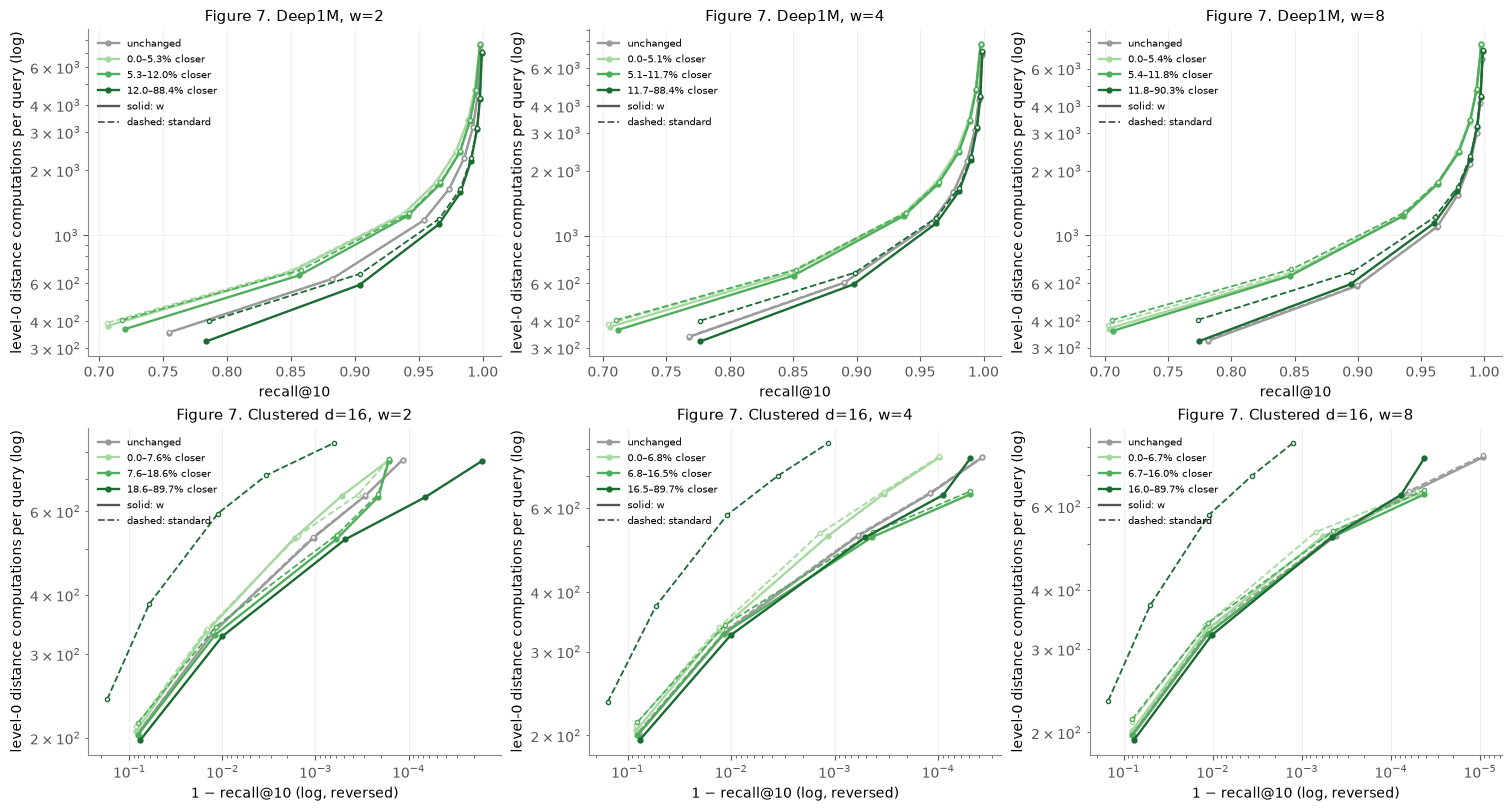

In [19]:
qg = rd.entry_gain_groups(queries)
groups = qg.attrs["group_names"]
gcurves = rd.group_curves(qg)
gmatched = rd.group_matched(gcurves)

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for i, ds in enumerate(rd.GT_DATASETS):
    for j, w in enumerate(rd.WS):
        ax = axes[i, j]
        ax.set_yscale("log")
        x = rp.recall_axis(ax, ds)
        rp.group_recall_cost(ax, gcurves[(gcurves.dataset == ds) & (gcurves.width == w)], groups[(ds, w)], x=x)
        ax.set_title(f"Figure 7. {ds}, w={w}")
        ax.legend(fontsize=7.5, loc="upper left")
plt.show()

**Entry-gain distribution.** How many queries get an entry point that is x% closer under w, before grouping them.
Each line is the share of queries at least x% closer (seeds pooled, log x); it starts at the share whose ep1 changed, the rest are unchanged.
Ticks on the Deep1M and Clustered d=16 lines are the group edges used in Figures 7–8, so each group between ticks holds a third of the changed queries.

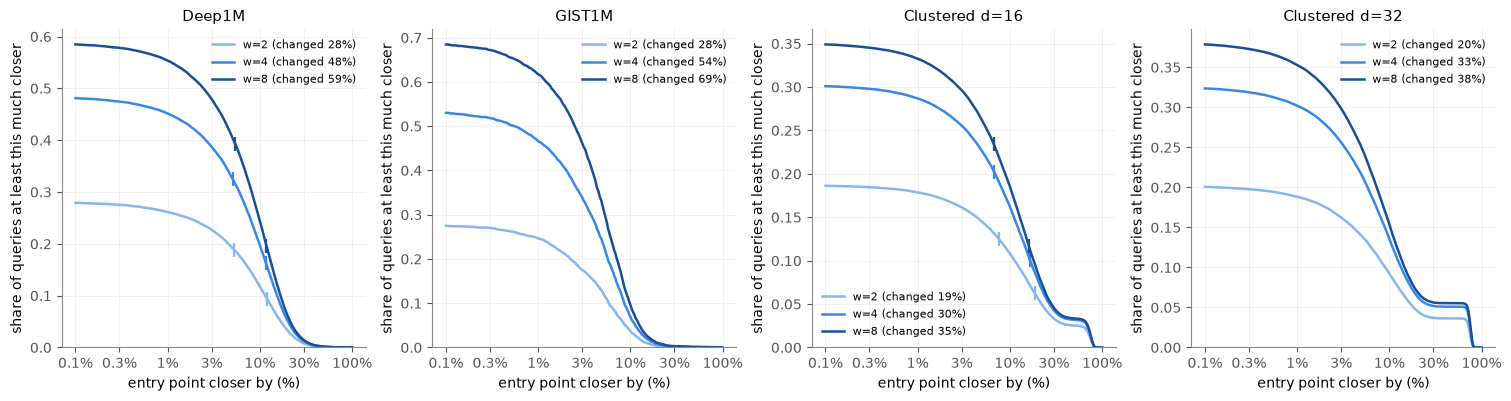

queries  unchanged  at_least_5pct  at_least_10pct  at_least_30pct  changed_p25  changed_p50  changed_p75  changed_p90
dataset        width                                                                                                                       
Deep1M         2        50000      0.719          0.192           0.117           0.008        3.943        8.356       14.274       21.046
               4        50000      0.515          0.327           0.197           0.012        3.807        8.120       13.961       20.442
               8        50000      0.412          0.406           0.244           0.014        4.053        8.334       13.996       20.288
GIST1M         2         5000      0.720          0.125           0.037           0.001        1.986        4.432        7.445       11.165
               4         5000      0.463          0.236           0.070           0.002        1.985        4.335        7.521       11.033
               8         5000      0.308          0.320           0.096           0.003        2.282        4.580        7.789       11.306
Clustered d=16 2       100000      0.813          0.145           0.108           0.033        5.556       12.329       23.133       69.181
               4       100000      0.697          0.226           0.162           0.043        4.928       10.935       20.462       61.936
               8       100000      0.649          0.261           0.186           0.046        4.888       10.722       19.790       39.935
Clustered d=32 2       100000      0.798          0.140           0.092           0.037        3.929        8.894       18.136       74.153
               4       100000      0.674          0.216           0.135           0.052        3.539        8.016       16.040       73.917
               8       100000      0.619          0.250           0.153           0.056        3.476        7.784       15.208       73.631

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), constrained_layout=True)
for ax, ds in zip(axes, rd.DATASETS):
    edges = {w: [float(n.split("–")[0]) for n in groups[(ds, w)][2:]] for w in rd.WS} if ds in rd.GT_DATASETS else None
    rp.entry_gain_survival(ax, queries[queries.dataset == ds], edges)
    ax.set_title(ds)
    ax.legend(fontsize=8)
plt.show()
display(rd.entry_gain_distribution(queries).round(3))

**Figure 7** shows the per-group recall–cost curves (seed means; solid w, dashed standard on the same queries). The horizontal gap between a pair is what the entry gain is worth at that recall.
**Figure 8** reads them at fixed recall targets: purple lines are the level-0 saving, one per target; the black dashed line is the extra level-1 work of the same queries. Where purple is above black, the wide search pays. Error bars are 95% t intervals across seeds.

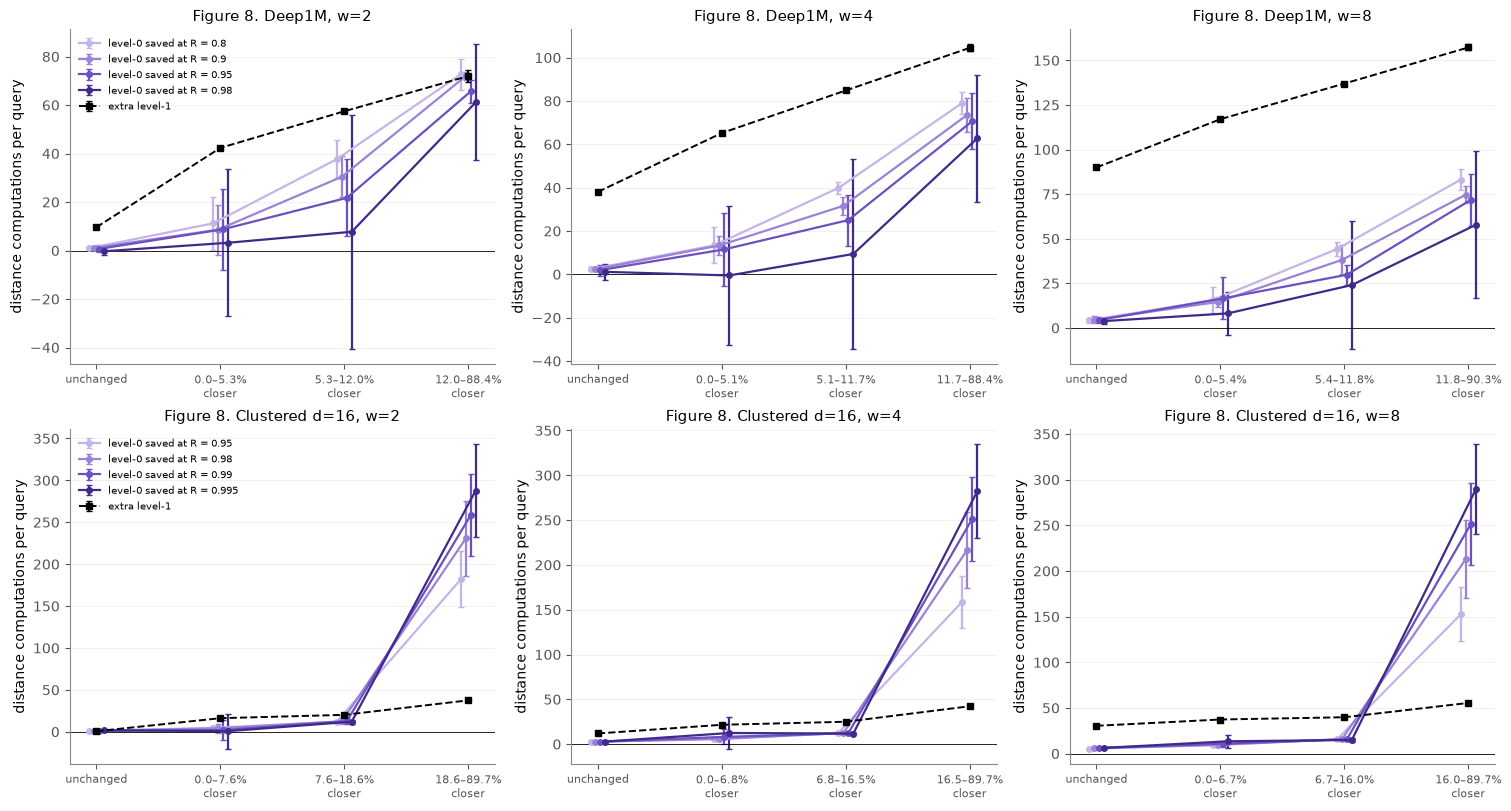

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for i, ds in enumerate(rd.GT_DATASETS):
    for j, w in enumerate(rd.WS):
        ax = axes[i, j]
        rp.group_balance(ax, gmatched[(gmatched.dataset == ds) & (gmatched.width == w)], groups[(ds, w)])
        ax.set_title(f"Figure 8. {ds}, w={w}")
        if j == 0:
            ax.legend(fontsize=7.5, loc="upper left")
plt.show()

In [22]:
print("Balance at matched recall per entry-gain group (seed mean, distance computations per query; net with its 95% t interval):")
bal = rd.across_seeds(gmatched, ["layer0_saved", "layer1_extra", "net_saved", "payback"], ["dataset", "width", "gain_group", "recall_target"])
tab = bal.xs("mean", axis=1, level=1).join(bal["net_saved"][["ci_lo", "ci_hi", "n_below_0"]].add_prefix("net_"))
per_group = gcurves.groupby(["dataset", "width", "gain_group"], observed=True).agg(queries_per_seed=("n_queries", "mean"), entry_gain_pct=("entry_gain_pct", "mean"))
display(tab.join(per_group, on=["dataset", "width", "gain_group"]).round(2))

Balance at matched recall per entry-gain group (seed mean, distance computations per query; net with its 95% t interval):


layer0_saved  layer1_extra  net_saved  payback  net_ci_lo  net_ci_hi  net_n_below_0  queries_per_seed  entry_gain_pct
dataset        width gain_group recall_target                                                                                                                       
Deep1M         2     0          0.800                  0.94          9.60      -8.66     0.10      -8.96      -8.35              5            7187.0        0.000000
                                0.900                  1.07          9.60      -8.53     0.11      -9.25      -7.81              5            7187.0        0.000000
                                0.950                  0.66          9.60      -8.94     0.07     -10.37      -7.50              5            7187.0        0.000000
                                0.980                 -0.30          9.60      -9.90    -0.03     -11.41      -8.38              5            7187.0        0.000000
                     1          0.800                 11.19         42.33     -31.14     0.27     -42.83     -19.44              5             937.6        2.580000
                                0.900                  8.59         42.33     -33.74     0.20     -44.53     -22.95              5             937.6        2.580000
                                0.950                  8.74         42.33     -33.58     0.21     -50.18     -16.99              5             937.6        2.580000
                                0.980                  3.19         42.33     -39.14     0.08     -69.73      -8.54              5             937.6        2.580000
                     2          0.800                 37.69         57.44     -19.75     0.66     -27.75     -11.75              5             937.6        8.450000
                                0.900                 30.42         57.44     -27.02     0.53     -35.67     -18.37              5             937.6        8.450000
                                0.950                 21.72         57.44     -35.72     0.38     -51.82     -19.62              5             937.6        8.450000
                                0.980                  7.73         57.44     -49.71     0.13     -97.95      -1.46              5             937.6        8.450000
                     3          0.800                 72.67         71.95       0.71     1.01      -5.95       7.38              2             937.8       19.540001
                                0.900                 71.95         71.95       0.00     1.00      -3.14       3.14              2             937.8       19.540001
                                0.950                 65.63         71.95      -6.32     0.91     -13.06       0.42              5             937.8       19.540001
                                0.980                 61.12         71.95     -10.83     0.85     -35.37      13.71              4             937.8       19.540001
               4     0          0.800                  2.34         38.06     -35.72     0.06     -36.59     -34.85              5            5153.8        0.000000
                                0.900                  2.37         38.06     -35.69     0.06     -36.95     -34.43              5            5153.8        0.000000
                                0.950                  1.96         38.06     -36.10     0.05     -38.68     -33.52              5            5153.8        0.000000
                                0.980                  1.14         38.06     -36.91     0.03     -40.33     -33.50              5            5153.8        0.000000
                     1          0.800                 13.43         65.23     -51.80     0.21     -60.09     -43.51              5            1615.4        2.510000
                                0.900                 13.32         65.23     -51.90     0.20     -56.78     -47.03              5            1615.4        2.510000
                                0.950                 11.53         65.23     -53.70   

## Figure 9. Tail of the per-query work at matched recall
**Question:** do the costliest queries gain or lose more than the average query? MQL is per batch, so a p95 latency is not available; per-query distance computations are.
**How:** per run, p95 over queries of total distance computations (all levels), then matched exactly as in Figure 3: the standard p95 curve is read at the w point's *mean* recall (log(1 − recall), same seed), Δ = 100 (p95_w / p95_std − 1).
Mean recall fixes the operating point but says nothing about the queries in the tail, so the table also gives the recall of each run's costliest 5% of queries, w minus standard at the same mean recall (Deep1M and Clustered d=16 only; the other two have no per-query recall).
GIST1M has 1,000 queries, so its p95 rests on 50 per run.
**Reading:** p95 moves with the mean. The clustered sets save slightly more in the tail than on average (d=32, w=2: −4.4% vs −3.7%), and Deep1M and GIST1M pay slightly less (w=8: +5.9% vs +6.4% on Deep1M, +4.6% vs +5.4% on GIST1M), most visibly at low recall.
The costliest queries keep their recall: within 0.4 recall points of standard on Deep1M (slightly lower) and within 0.2 on Clustered d=16.

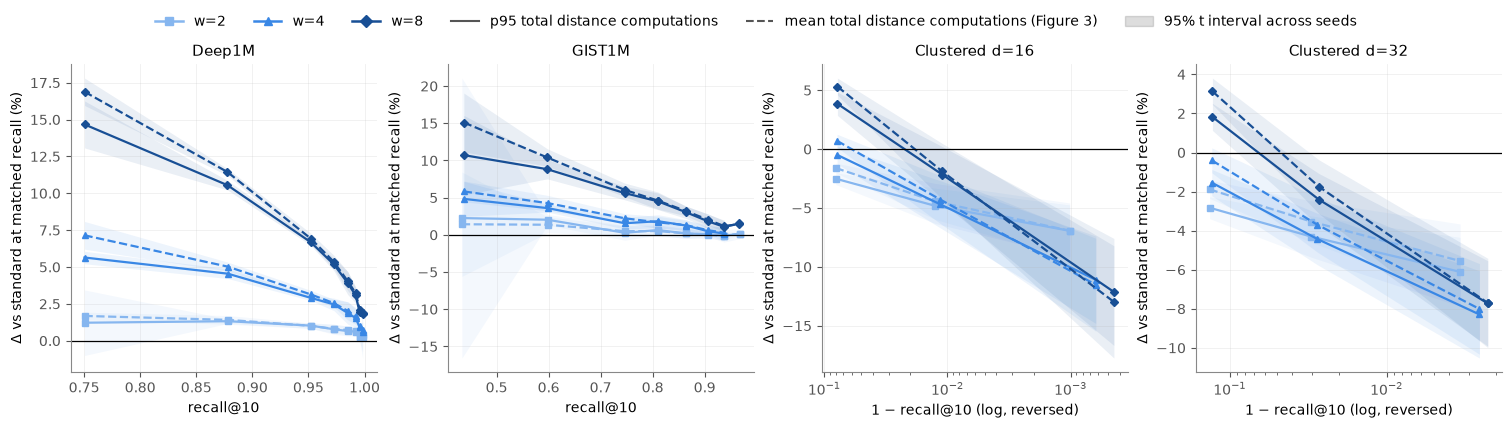

In [23]:
runs_t = rd.query_tails(DATA, runs)
tails = rd.tail_matched(runs_t)
P95 = f"dist_total_p{rd.TAIL_Q}"

fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), constrained_layout=True)
for ax, ds in zip(axes, rd.DATASETS):
    x = rp.recall_axis(ax, ds)
    rp.delta_vs_standard(ax, tails[tails.dataset == ds], x, [P95 + "_delta_pct", "dist_total_delta_pct"])
    ax.set_title(ds)
fig.get_layout_engine().set(rect=(0, 0, 1, 0.91))
rp.width_legend(fig, rd.WS, extra=[(f"p{rd.TAIL_Q} total distance computations", "-"), ("mean total distance computations (Figure 3)", "--")])
plt.show()

In [24]:
print(f"Matched recall, seed mean over ef0 then across seeds: Δ mean and Δ p{rd.TAIL_Q} total distance computations (%), "
      f"and Δ recall@10 of the costliest {100 - rd.TAIL_Q}% of queries (recall points, > 0 = w better):")
cols = ["mean", "ci_lo", "ci_hi", "n_below_0", "n_seeds"]
tail_tab = pd.concat({c: rd.matched_summary(tails, c)[cols]
                      for c in ["dist_total_delta_pct", P95 + "_delta_pct", "tail_recall_delta"]}, axis=1)
tail_tab[[("tail_recall_delta", c) for c in ["mean", "ci_lo", "ci_hi"]]] *= 100
display(tail_tab.round(3))
print("Per ef0, seed mean: absolute p95 and tail recall, standard and w:")
display(rd.across_seeds(runs_t, [P95, "tail_recall"], ["dataset", "ef0", "width"]).xs("mean", axis=1, level=1).unstack("width").round(3))

Matched recall, seed mean over ef0 then across seeds: Δ mean and Δ p95 total distance computations (%), and Δ recall@10 of the costliest 5% of queries (recall points, > 0 = w better):


dist_total_delta_pct                                 dist_total_p95_delta_pct                                 tail_recall_delta                                
                                     mean  ci_lo  ci_hi n_below_0 n_seeds                     mean  ci_lo  ci_hi n_below_0 n_seeds              mean  ci_lo  ci_hi n_below_0 n_seeds
dataset        width                                                                                                                                                                
Deep1M         2                    0.837  0.735  0.939         0       5                    0.768  0.659  0.877         0       5            -0.139 -0.215 -0.062       5.0     5.0
               4                    2.845  2.259  3.432         0       5                    2.551  2.029  3.074         0       5            -0.227 -0.464  0.010       4.0     5.0
               8                    6.387  5.068  7.707         0       5                    5.937  4.786  7.088         0       5            -0.392 -0.518 -0.267       5.0     5.0
GIST1M         2                    0.422 -0.116  0.960         1       5                    0.555 -0.011  1.120         0       5               NaN    NaN    NaN       NaN     NaN
               4                    2.203  1.682  2.725         0       5                    1.876  1.680  2.073         0       5               NaN    NaN    NaN       NaN     NaN
               8                    5.370  3.704  7.036         0       5                    4.621  3.464  5.778         0       5               NaN    NaN    NaN       NaN     NaN
Clustered d=16 2                   -4.327 -5.609 -3.046        10      10                   -4.757 -6.013 -3.501        10      10             0.070 -0.064  0.204       5.0    10.0
               4                   -5.037 -6.973 -3.101         9      10                   -5.426 -7.364 -3.488         9      10             0.045 -0.078  0.168       4.0    10.0
               8                   -3.184 -5.598 -0.770         8      10                   -3.480 -5.917 -1.042         9      10             0.053 -0.092  0.198       4.0    10.0
Clustered d=32 2                   -3.660 -4.690 -2.631        10      10                   -4.415 -5.433 -3.397        10      10               NaN    NaN    NaN       NaN     NaN
               4                   -4.035 -5.390 -2.680        10      10                   -4.753 -6.079 -3.427        10      10               NaN    NaN    NaN       NaN     NaN
               8                   -2.106 -3.454 -0.759         9      10                   -2.773 -4.069 -1.477         9      10               NaN    NaN    NaN       NaN     NaN

Per ef0, seed mean: absolute p95 and tail recall, standard and w:


dist_total_p95                                  tail_recall                     
width                           1          2          4          8           1      2      4      8
dataset        ef0                                                                                 
Deep1M         10         711.000    722.200    755.010    819.400       0.653  0.641  0.637  0.629
               23        1074.400   1087.800   1121.000   1183.800       0.750  0.746  0.747  0.742
               52        1839.210   1855.010   1888.620   1955.620       0.882  0.880  0.880  0.878
               79        2523.410   2539.430   2577.820   2645.040       0.929  0.927  0.928  0.927
               120       3502.810   3518.640   3558.230   3630.630       0.956  0.956  0.955  0.955
               182       4886.650   4904.420   4945.040   5018.840       0.974  0.974  0.974  0.973
               275       6794.260   6814.220   6859.030   6930.630       0.982  0.982  0.982  0.982
               512      11143.060  11162.310  11211.070  11288.060       0.992  0.992  0.992  0.992
GIST1M         10         852.060    870.480    898.090    957.240         NaN    NaN    NaN    NaN
               23        1318.300   1343.890   1365.040   1431.620         NaN    NaN    NaN    NaN
               52        2169.400   2180.680   2211.270   2295.480         NaN    NaN    NaN    NaN
               79        2916.140   2936.900   2976.300   3047.700         NaN    NaN    NaN    NaN
               120       4037.470   4054.050   4093.980   4171.220         NaN    NaN    NaN    NaN
               182       5625.560   5647.640   5681.660   5762.400         NaN    NaN    NaN    NaN
               275       7829.360   7850.960   7887.190   7975.590         NaN    NaN    NaN    NaN
               512      12881.030  12893.910  12947.900  13038.850         NaN    NaN    NaN    NaN
Clustered d=16 10         370.105    366.400    375.905    392.800       0.932  0.934  0.935  0.935
               23         502.905    497.900    506.500    523.010       0.990  0.991  0.992  0.993
               52         703.000    697.000    705.600    721.905       0.998  1.000  0.999  1.000
               79         822.400    816.600    826.100    842.710       0.999  1.000  1.000  1.000
               120        946.405    941.200    951.610    969.505       1.000  1.000  1.000  1.000
Clustered d=32 10         453.510    448.900    458.505    475.200         NaN    NaN    NaN    NaN
               23         617.400    609.105    617.705    633.500         NaN    NaN    NaN    NaN
               52         842.700    830.800    838.900    854.805         NaN    NaN    NaN    NaN
               79         961.105    948.800    957.000    973.410         NaN    NaN    NaN    NaN
               120       1068.110   1056.300   1065.000   1082.300         NaN    NaN    NaN    NaN